# 02 · 前端 Web 开发（JS + Vue + Ajax）


来源：[飞书讲义《02-前端Web开发(JS+Vue+Ajax)》](https://heuqqdmbyk.feishu.cn/wiki/FxTdw2K9mieDgAkhSqucg59Cn8f)。整理日期：2026-09-27。

本章接着第一章的员工管理页学习：先用 JavaScript 操作 DOM 和监听事件，再用 Vue 3 管理界面数据，最后通过 Axios 获取员工列表，并在页面挂载后自动查询。按原讲义顺序完整保留知识说明、47 段代码、5 张嵌入知识表格、27 张配图与动图、AI 提示词和接口地址。

原例中有意演示的报错、需要上下文的方法片段，以及影响运行的笔误，均在附近说明。第 7 节补齐了可直接保存的最终页面与本地 JSON 练习数据。配图已内嵌，可离线阅读；运行引用 Vue、Axios 或远程接口的代码，仍需准备依赖与可访问的数据源。


## 1 介绍

在前面的课程中，我们已经学习了HTML、CSS的基础内容，我们知道HTML负责网页的结构，而CSS负责的是网页的表现。 而要想让网页具备一定的交互效果，具有一定的动作行为，还得通过JavaScript来实现。那今天,我们就来讲解JavaScript，这门语言会让我们的页面能够和用户进行交互。

<strong>那什么是JavaScript呢 ?</strong>

<strong>JavaScript</strong>（简称：<strong>JS</strong>） 是一门跨平台、面向对象的脚本语言，是用来控制网页行为的，实现人机交互效果。JavaScript 和 Java 是完全不同的语言，不论是概念还是设计。但是基础语法类似。

- 组成：

    - ECMAScript: 规定了JS基础语法核心知识，包括变量、数据类型、流程控制、函数、对象等。
    - BOM：浏览器对象模型，用于操作浏览器本身，如：页面弹窗、地址栏操作、关闭窗口等。
    - DOM：文档对象模型，用于操作HTML文档，如：改变标签内的内容、改变标签内字体样式等。

> 备注：ECMA国际（前身为欧洲计算机制造商协会），制定了标准化的脚本程序设计语言 ECMAScript，这种语言得到广泛应用。而JavaScript是遵守ECMAScript的标准的（ES2024是最新版本）。
> 
> > **时效说明：**“ES2024 是最新版本”是原讲义编写时的描述。ECMAScript 持续演进，本章使用的 `let`、`const`、箭头函数、模块和 `async/await` 等语法，重点是理解用法与运行环境支持。


## 2 JS 核心语法


### 2.1 JS引入方式

同样，js代码也是书写在html中的，那么html中如何引入js代码呢？主要通过下面的2种引入方式：

- 第一种方式：内部脚本，将JS代码定义在HTML页面中

    - JavaScript代码必须位于&lt;script&gt;&lt;/script&gt;标签之间
    - 在HTML文档中，可以在任意地方，放置任意数量的&lt;script&gt;&lt;/script&gt;
    - 一般会把脚本置于&lt;body&gt;元素的底部，可改善显示速度
    - 例子：

    ````html
    <!DOCTYPE html>
    <html lang="en">
    <head>
      <meta charset="UTF-8">
      <meta name="viewport" content="width=device-width, initial-scale=1.0">
      <title>JS 引入方式</title>
    </head>
    <body>
      
      <script>
        alert('Hello JS')
      </script>
    </body>
    </html>
    ````

- 第二种方式：外部脚本， 将JS代码定义在外部 JS文件中，然后引入到 HTML页面中

    - 外部JS文件中，只包含JS代码，不包含&lt;script&gt;标签
    - 引入外部js的&lt;script&gt;标签，必须是双标签
    - 例子：

        - 在js目录下，定义一个js文件<code>demo.js</code>，在文件中编写js代码，如下：

        ````javascript
        alert('Hello JS')
        ````

        - 在html文件中，通过&lt;script&gt;&lt;/script&gt;引入js文件<code>demo.js</code>，如下：

        ````html
        <script src="js/demo.js"></script>
        ````
    - <strong>注意1：demo.js中只有js代码，没有&lt;script&gt;标签</strong>
    - <strong>注意2：通过&lt;script&gt;&lt;/script&gt;标签引入外部JS文件时，标签不能自闭合，如：&lt;script src="js/demo.js" /&gt;</strong>

- JS书写规范：

    - 结束符：每行js代码，结尾以分号结尾，而结尾的分号可有可无。（建议在一个项目中保持一致，要么全部都加，要么全部都不加）

    > **补充：**JavaScript 有自动分号插入机制，但换行并不总能替代分号。本章练习建议保留分号；例如 `return` 后立刻换行，可能提前结束返回语句。
    - 注释：单行注释，多行注解的写法， 与java中一致。


### 2.2 JS基础语法


#### 2.2.1 输出语句

在JS中有3种输出语句，分别是：

| api | 描述 |
| --- | --- |
| window.alert(...) | 警告框 |
| document.write(...) | 在HTML 输出内容 |
| console.log(...) | 写入浏览器控制台 |

> **补充：**`console.log` 的输出在浏览器开发者工具的“控制台 / Console”里查看。`alert` 是会暂停当前脚本等待确认的弹窗；`document.write` 属于旧式输出方式，在页面加载结束后使用可能覆盖原页面，后面的交互代码应通过 DOM 或 Vue 更新内容。

我们定义如下这么一段JS，来做一个测试：

````html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>JS基础语法</title>
</head>
<body>
        
    <script>
        //方式一: 写入浏览器的body区域
        document.write("Hello JS (document.write)");

        //方式二: 弹出框
        window.alert("Hello JS (window.alert)");

        //方式三: 控制台
        console.log("Hello JS (console.log)")
    </script>
</body>
</html>
````


#### 2.2.2 变量

> **补充：**`let` 是块级作用域，同一作用域不能重复声明同名变量；`var` 主要是函数作用域，允许某些重复声明，并有变量提升行为。变量暂时不重新赋值时可以优先使用 `const`，需要重新赋值时使用 `let`。

接下来，我们再来讲解JS中的变量。在js中，变量的声明和java中还是不同的。

- JS中主要通过 <code>let</code> 关键字来声明变量的。
- JS是一门弱类型语言，变量是可以存放不同类型的值的。
- 变量名需要遵循如下规则：

    - 组成字符可以是任何字母、数字、下划线（&#95;）或美元符号（&#36;），且数字不能开头
    - 变量名严格区分大小写，如：name和Name是不同的变量
    - 不能使用关键字作为变量名，如：let、if、for等

变量的声明示例如下所示：

````html
<script>
    //变量
    let a = 20;
    a = "Hello";
    alert(a);
</script>
````

上述的示例中，大家会看到变量a既可以存数字，又可以存字符串。 因为JS是弱类型语言。

> PS. 在早期的JS中，声明变量还可以使用 <code>var</code> 关键字来声明。例如:
> 
> ````html
> <body>
> 
>     <script>
>         //var声明变量
>         var name = "A";
>         name = "B";
>         alert(name);
>         
>         var name = "C"
>         alert(name);
>     </script>
> </body>
> ````
> 
> 打开浏览器运行之后，大家会发现，可以正常执行，第一次弹出 B，第二次弹出 C 。我们看到 name变量重复声明了，但是呢，如果使用var关键字，是没有问题的，可以重复声明。
> 
> <strong><code>var</code></strong><strong>声明的变量呢，还有一些其他不严谨的地方，这里就不再一一列举了，所以这个声明变量的关键字，并不严谨 【不推荐】。</strong>


#### 2.2.3 常量

在JS中，如果声明一个场景，需要使用<code>const</code>关键字。一旦声明，常量的值就不能改变 （不可以重新赋值）。

> **勘误：**这里的“场景”应为“常量”。`const` 必须在声明时初始化，限制的是变量绑定不能重新赋值，不等于对象内部内容不能修改。

如下所示：

````html
<body>

    <script>
        //常量
        const PI = 3.14;
        PI = 3.15;
        alert(PI);
    </script>
</body>
````

> **示例说明：**这段代码有意演示错误：执行 `PI = 3.15` 时抛出 `TypeError`，后面的 `alert(PI)` 不再执行。

**补充：对象内容与变量重新赋值的区别。**

```javascript
const user = { name: 'Tom' };
user.name = 'Jerry';       // 可以：修改对象属性
console.log(user.name);    // Jerry
// user = { name: 'Jack' }; // 不可以：给 const 变量重新赋值
```

浏览器打开之后，会报如下错误：

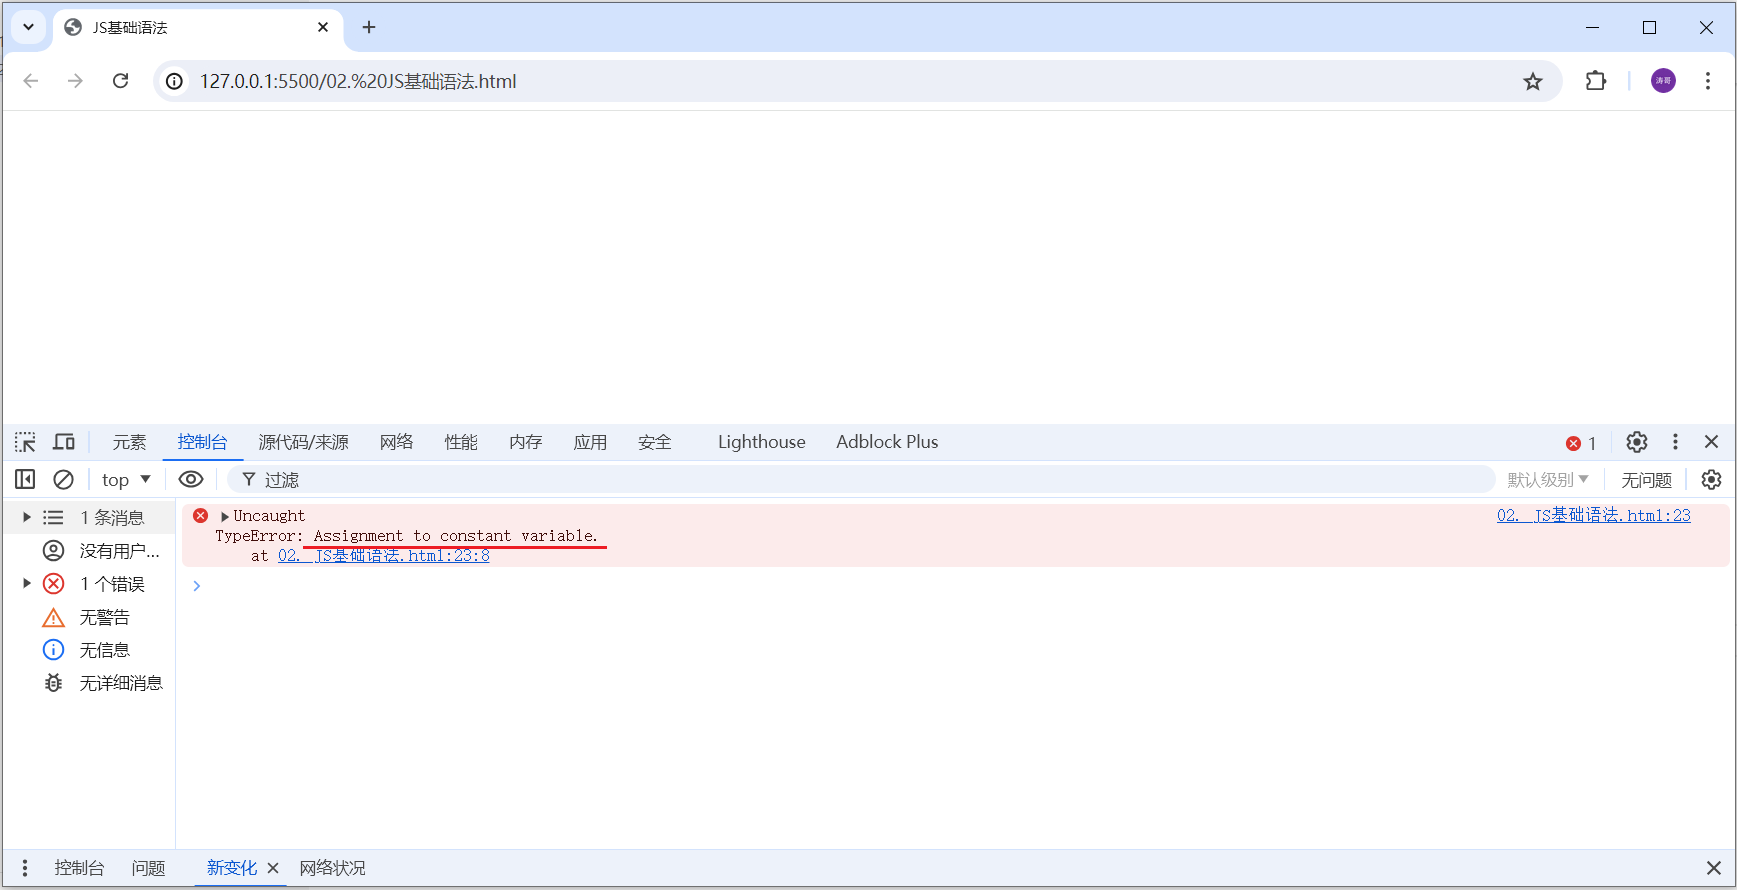

该错误就表示，常量不可以被重新分配值。


#### 2.2.4 数据类型

虽然JS是弱数据类型的语言，但是JS中也存在数据类型，JS中的数据类型分为 ：原始数据类型 和 引用数据类型。那这部分，我们先来学习原始数据类型，主要包含以下几种类型：

| 数据类型 | 描述 |
| --- | --- |
| number | 数字（整数、小数、NaN(Not a Number)） |
| string | 字符串，单双引('...')、双引号("...")、反引号(&#96;...&#96;)皆可，正常使用推荐单引号 |
| boolean | 布尔。true，false |
| null | 对象为空。 JavaScript 是大小写敏感的，因此 null、Null、NULL是完全不同的 |
| undefined | 当声明的变量未初始化时，该变量的默认值是 undefined |

> **勘误：**`null` 本身是原始值，不是一个“空对象”。`typeof null` 返回 `"object"` 是历史遗留行为；判断空值可直接用 `value === null`。`typeof` 是运算符，返回的是表示类型的字符串。
>
> **补充：**本表列的是本章重点，现代 JavaScript 的原始类型还包括 `bigint`、`symbol`；对象、数组和函数属于对象这一大类。普通整数和小数都属于 `number`；`typeof NaN` 也是 `"number"`，它表示无效数值计算的结果。变量可改存其他类型，更准确地说体现的是“动态类型”；自动类型转换是另一个相关但不同的概念。

使用<code>typeof</code> 关键字可以返回变量的数据类型，接下来我们需要通过书写代码来演示js中的数据类型。代码如下:

````html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>JS-数据类型</title>
</head>
<body>

    <script>
        //原始数据类型
        alert(typeof 3); //number
        alert(typeof 3.14); //number

        alert(typeof "A"); //string
        alert(typeof 'Hello');//string

        alert(typeof true); //boolean
        alert(typeof false);//boolean

        alert(typeof null); //object 

        var a ;
        alert(typeof a); //undefined

    </script>
</body>
</html>
````

对于字符串类型的数据，除了可以使用双引号（"..."）、单引号（'...'）以外，还可以使用反引号 （&#96;&#96;）。 而使用反引号引起来的字符串，也称为 <strong>模板字符串</strong>。

- 模板字符串的使用场景：拼接字符串和变量。
- 模板字符串的语法：

    - &#96;...&#96; ：反引号 （英文输入模式下键盘 tab 键上方波浪线 &#126; 那个键）
    - 内容拼接时，使用 &#36;{ } 来引用变量

具体示例如下：

````html
  <script>
    let name = 'Tom';
    let age = 18;
    console.log('大家好, 我是新入职的' + name + ', 今年' + age + '岁了, 请多多关照'); //原始方式 , 手动拼接字符串
    console.log(`大家好, 我是新入职的${name}, 今年${age}岁了, 请多多关照`); //使用模板字符串方式拼接字符串
  </script>
````


#### 2.2.5 函数

<strong>函数（function）</strong>是被设计用来执行特定任务的代码块，方便程序的封装复用。 那我们学习函数，主要就是学习JS中函数的定义及调用的语法。

##### 2.2.5.1 方式一

格式如下：

````javascript
function 函数名(参数1,参数2..){
    要执行的代码
}
````

因为JavaScript是弱数据类型的语言，所以有如下几点需要注意：

- 形参不需要声明类型，并且JS中不管什么类型都是let去声明，加上也没有意义。

> **勘误：**形参列表直接写参数名，不能写 `function add(let a, let b)`。函数参数也不是“必须由 let 声明”；它们由函数参数语法建立绑定。
- 返回值也不需要声明类型，直接return即可

<strong>示例：</strong>

````javascript
function add(a, b){
    return a + b;
}
````

如果要调用上述的函数add，可以使用：函数名称(实际参数列表)

````javascript
let result = add(10,20);
alert(result);
````

我们在调用add函数时，再添加2个参数，修改代码如下：

````javascript
var result = add(10,20,30,40);
alert(result);
````

浏览器打开，发现没有错误，并且依然弹出30，这是为什么呢？

因为在JavaScript中，函数的调用只需要名称正确即可，参数列表不管的。如上述案例，10传递给了变量a，20传递给了变量b，而30和40没有变量接受，但是不影响函数的正常调用。

> **勘误：**JavaScript 不要求实参与形参数量严格相等，但传入值仍会影响运行结果。多余参数在当前 `add` 实现中没有被使用；缺少参数时，相应形参为 `undefined`。没有显式 `return` 时，函数默认返回 `undefined`。

```javascript
function add(a, b) {
  return a + b;
}
console.log(add(10, 20, 30)); // 30：当前函数只使用前两个参数
console.log(add(10));         // NaN：10 + undefined
console.log(add('10', 20));   // "1020"：+ 遇到字符串可能拼接
```

<strong>注意：由于JS是弱类型语言，形参、返回值都不需要指定类型。在调用函数时，实参个数与形参个数可以不一致，但是建议一致。 </strong>

##### 2.2.5.2 方式二

刚才我们定义函数，是为函数指定了一个名字。 那我们也可以不为函数指定名字，那这一类的函数，我们称之为<strong>匿名函数</strong>。那接下来，方式二，就来介绍一下匿名函数的定义和调用。

<strong>匿名函数：</strong>是指一种没有名称的函数，由于它们没有名称，因此无法直接通过函数名来调用，而是通过变量或表达式来调用。

匿名函数定义可以通过两种方式：函数表达式 和 箭头函数。

- 示例一（函数表达式）：

````javascript
var add = function (a,b){
    return a + b;
}
````

- 示例二（<strong>箭头函数</strong>）：

````javascript
var add = (a,b) => {
    return a + b;
}
````

上述匿名函数声明好了之后，是将这个函数赋值给了add变量。 那我们就可以直接通过add函数直接调用，调用代码如下：

````javascript
let result = add(10,20);
alert(result);
````

而箭头函数这种形式，在现在的前端开发中用的会更多一些。

##### 2.2.5.3 自定义对象

在 JavaScript 中自定义对象特别简单，其语法格式如下：

````javascript
let 对象名 = {
    属性名1: 属性值1,
    属性名2: 属性值2,
    属性名3: 属性值3,
    方法名称: function(形参列表){}
};
````

我们可以通过如下语法调用属性：

````javascript
对象名.属性名
````

通过如下语法调用函数：

````javascript
对象名.方法名()
````

代码演示：

````javascript
<script>
    //自定义对象
    let user = {
        name: "Tom",
        age: 10,
        gender: "男",
        sing: function(){
             console.log("悠悠的唱着最炫的民族风~");
         }
    }

    console.log(user.name);
    user.eat();
<script>
````

> **勘误：**原例定义的是 `sing`，调用却写成了 `user.eat()`，并把结束标签误写为 `<script>`。应调用 `user.sing()` 并正确闭合脚本。下面是可单独运行的版本，方法简写与上面的 `sing: function () { ... }` 作用对应。

```html
<!DOCTYPE html>
<html lang="zh-CN">
<head><meta charset="UTF-8"><title>自定义对象</title></head>
<body>
  <script>
    const user = {
      name: 'Tom',
      age: 10,
      gender: '男',
      sing() {
        console.log('悠悠的唱着最炫的民族风~');
      }
    };
    console.log(user.name);
    user.sing();
  </script>
</body>
</html>
```

浏览器控制台结果如下：

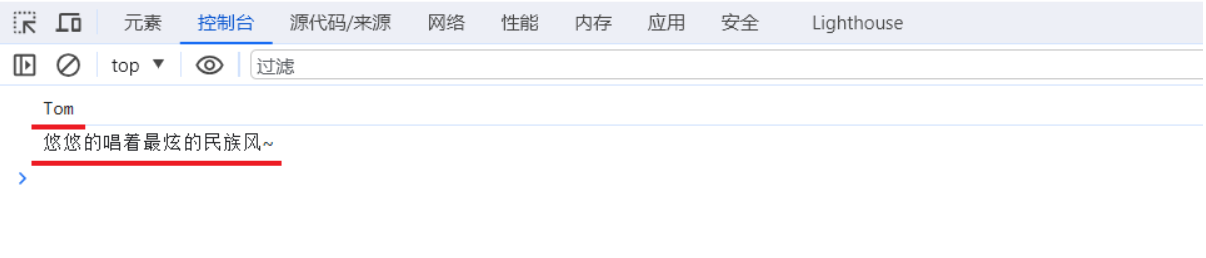

其中，上述函数定义的语法可以简化成如下格式：

````javascript
<script>
    //自定义对象
    let user = {
        name: "Tom",
        age: 10,
        gender: "男",
        sing(){
             console.log("悠悠的唱着最炫的民族风~");
         }
    }
    
    console.log(user.name);
    user.eat();
<script>
````

> **勘误：**原例定义的是 `sing`，调用却写成了 `user.eat()`，并把结束标签误写为 `<script>`。应调用 `user.sing()` 并正确闭合脚本。下面是可单独运行的版本，方法简写与上面的 `sing: function () { ... }` 作用对应。

```html
<!DOCTYPE html>
<html lang="zh-CN">
<head><meta charset="UTF-8"><title>自定义对象</title></head>
<body>
  <script>
    const user = {
      name: 'Tom',
      age: 10,
      gender: '男',
      sing() {
        console.log('悠悠的唱着最炫的民族风~');
      }
    };
    console.log(user.name);
    user.sing();
  </script>
</body>
</html>
```

##### 2.2.5.4 JSON

JSON对象：<strong>J</strong>ava<strong>S</strong>cript <strong>O</strong>bject <strong>N</strong>otation，JavaScript对象标记法。JSON是通过JavaScript标记法书写的文本。其格式如下：

````javascript
{
    "key":value,
    "key":value,
    "key":value
}
````

其中，<strong>key必须使用引号并且是双引号标记，value可以是任意数据类型。</strong>

> **勘误：**JSON 是文本数据格式，值只允许字符串、数值、布尔值、`null`、数组和对象；不能直接放入函数、`undefined`、`Symbol` 或 `BigInt`，也不能有注释和尾随逗号。属性名和字符串值使用双引号。
>
> JavaScript 对象与 JSON 字符串不是同一种东西：`JSON.stringify` 将可序列化的数据转换为字符串；`JSON.parse` 解析合法 JSON，格式错误会抛出异常。上面重复的 `"key": value` 是结构示意，不是可以直接提交的有效业务数据。

而由于语法简单，层级结构鲜明，现多用于作为数据载体，在网络中进行数据传输。

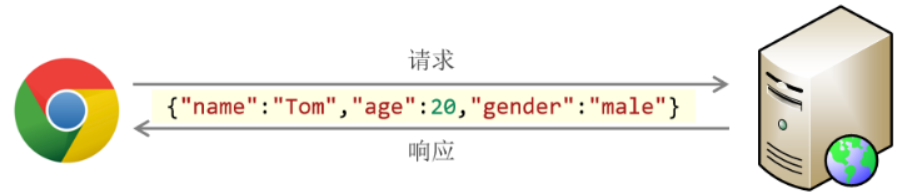

代码演示:

````javascript
//3. JSON - JS对象标记法
let person = {
  name: 'itcast',
  age: 18,
  gender: '男'
}
alert(JSON.stringify(person)); //js对象 --> json字符串

let personJson = '{"name": "heima", "age": 18}';
alert(JSON.parse(personJson).name);
````

API说明：

> JSON.stringify(...)：作用就是将js对象，转换为json格式的字符串。
> 
> JSON.parse(...)：作用就是将json格式的字符串，转为js对象。


#### 2.2.6 流程控制

在JS中，当然也存在对应的流程控制语句。常见的流程控制语句如下：

- if ... else if ... else ...
- switch
- for
- while
- do ... while

而JS中的流程控制语句与JAVA中的流程控制语句的作用，执行机制都是一样的。这个呢，我们现在就不再一个一个的如研究了，后面用到的时候，我们再做说明。

> **补充：**控制流程的整体思路可以沿用 Java，但 JavaScript 条件判断会进行真值转换。`false`、`0`、空字符串、`null`、`undefined`、`NaN` 等是假值，字符串 `"0"`、`"false"` 以及空数组、空对象都是真值。
>
> 后面的职位与性别判断会用到 `===` 和 `==`：`===` 不做类型转换，`1 === '1'` 为 `false`；`==` 会做转换，`1 == '1'` 为 `true`。接口数据与表单数据应先统一类型，再用严格比较。


#### 2.2.7 JS DOM

##### 2.2.7.1 DOM介绍

DOM：Document Object Model 文档对象模型。也就是 JavaScript 将 HTML 文档的各个组成部分封装为对象。

DOM 其实我们并不陌生，之前在学习 XML 就接触过，只不过 XML 文档中的标签需要我们写代码解析，而 HTML 文档是浏览器解析。封装的对象分为

- Document：整个文档对象
- Element：元素对象
- Attribute：属性对象
- Text：文本对象
- Comment：注释对象

如下图，左边是 HTML 文档内容，右边是 DOM 树

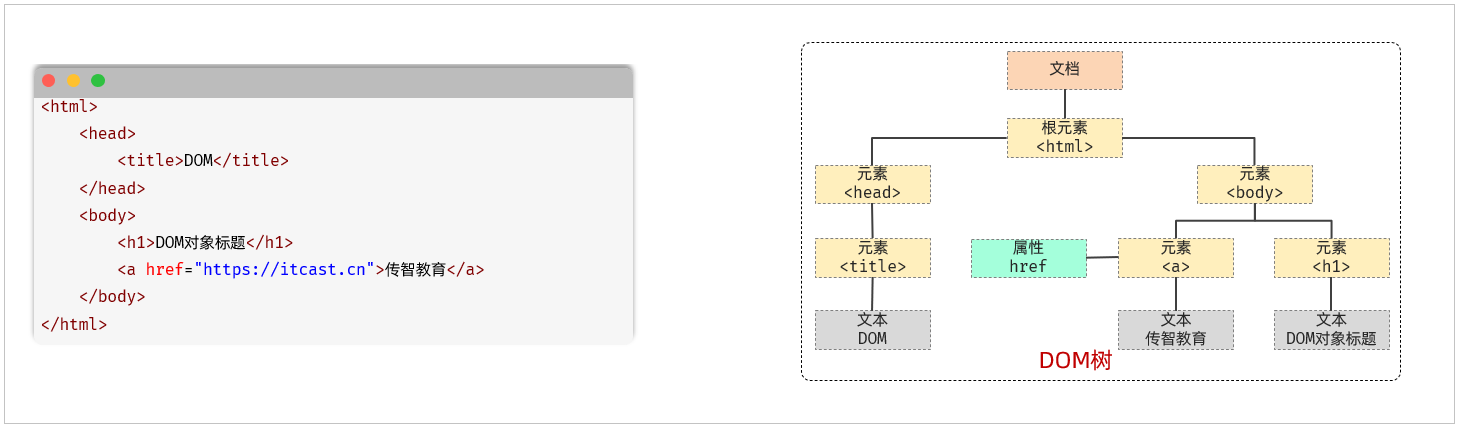

那么我们学习DOM技术有什么用呢？主要作用如下：

- 改变 HTML 元素的内容
- 改变 HTML 元素的样式（CSS）
- 对 HTML DOM 事件作出反应
- 添加和删除 HTML 元素

##### 2.2.7.2 DOM操作

- DOM的核心思想：将网页的内容当做对象来处理，标签的所有属性在该对象上都可以找到，并且修改这个对象的属性，就会自动映射到标签身上。
- document对象

    - 网页中所有内容都封装在document对象中
    - 它提供的属性和方法都是用来访问和操作网页内容的，如：document.write(…)
- DOM操作步骤:

    - 获取DOM元素对象
    - 操作DOM对象的属性或方法 (查阅文档)

- 我们可以通过如下两种方式来获取DOM元素。

    1. 根据CSS选择器来获取DOM元素，获取到匹配到的第一个元素：<code>document.querySelector(</code><code>'</code><code>CSS选择器</code><code>'</code><code>);</code>
    2. 根据CSS选择器来获取DOM元素，获取匹配到的所有元素：<code>document.querySelectorAll('CSS选择器');</code>

         注意：获取到的所有元素，会封装到一个NodeList节点集合中，是一个伪数组（有长度、有索引的数组，但没有push、pop等数组方法）

<strong>代码演示:</strong>

````html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>JS-DOM</title>
</head>
<body>

  <h1 id="title1">11111</h1>
  <h1>22222</h1>
  <h1>33333</h1>

  <script>
    //1. 修改第一个h1标签中的文本内容
    //1.1 获取DOM对象
    // let h1 = document.querySelector('#title1');
    //let h1 = document.querySelector('h1'); // 获取第一个h1标签

    let hs = document.querySelectorAll('h1');

    //1.2 调用DOM对象中属性或方法
    hs[0].innerHTML = '修改后的文本内容';
  </script>
</body>
</html>
````

> **补充：**`querySelector` 没找到元素时返回 `null`；`querySelectorAll` 没找到时返回空 `NodeList`，直接访问 `hs[0].innerHTML` 会报错。脚本要在目标标签已经出现后执行，可放在 `body` 底部；外部经典脚本也可配合 `defer`。
>
> `innerHTML` 会把字符串当作 HTML 解析，`textContent` 只写入文字。这里只改标题文字时可写 `hs[0].textContent = '修改后的文本内容'`。来自用户或接口的普通文字优先用 `textContent`，避免被解释成标签。

> PS：在早期的JS中，我们也可以通过如下方法获取DOM元素（了解）。
> 
> - document.getElementById(...)：根据id属性值获取，返回单个Element对象。
> - document.getElementsByTagName(...)：根据标签名称获取，返回Element对象数组。
> - document.getElementsByName()：根据name属性值获取，返回Element对象数组。
> - document.getElementsByClassName()：根据class属性值获取，返回Element对象数组。
> 
> > **勘误：**这些返回值不是普通数组。`getElementsByTagName` 和 `getElementsByClassName` 返回动态的 `HTMLCollection`；`getElementsByName` 返回动态 `NodeList`。`querySelectorAll` 返回静态 `NodeList`，可以遍历，但不能直接当作具备 `push/pop` 的数组。


## 3 JS 事件监听


### 3.1 事件介绍

什么是事件呢？HTML事件是发生在HTML元素上的 “事情”，例如：

- 按钮被点击
- 鼠标移到元素上
- 输入框失去焦点
- 按下键盘按键
- ........

而我们可以给这些事件绑定函数，当事件触发时，可以自动的完成对应的功能，这就是事件监听。

例如：对于我们所说的百度注册页面，我们给用户名输入框的失去焦点事件绑定函数，当我们用户输入完内容，在标签外点击了鼠标，对于用户名输入框来说，失去焦点，然后执行绑定的函数，函数进行用户名内容的校验等操作。

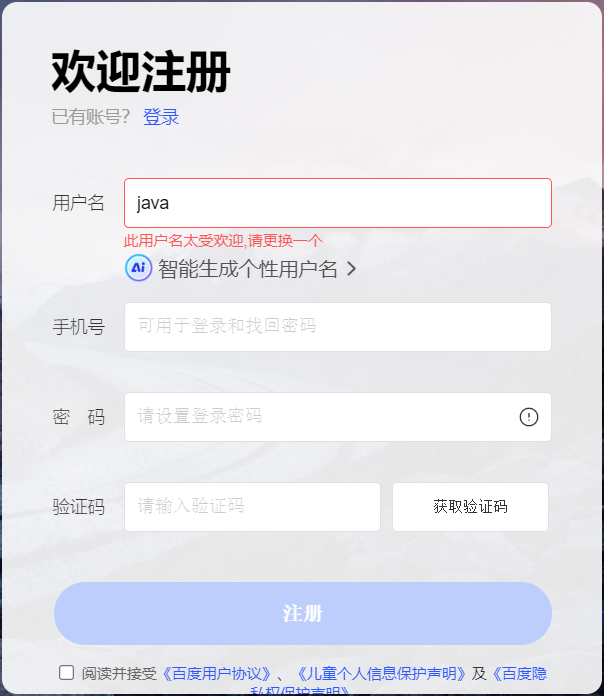

JS事件是JS非常重要的一部分，接下来我们进行事件的学习。那么我们对于JavaScript事件需要学习哪些内容呢？我们得知道有哪些常用事件，然后我们得学会如何给事件绑定函数。

所以主要围绕2点来学习：①. 事件监听、②. 常用事件


### 3.2 事件监听语法

JS事件监听的语法: 

````javascript
事件源.addEventListener('事件类型', 要执行的函数);
````

> **补充：**传入的是函数本身，例如 `button.addEventListener("click", handle)`，不是 `handle()` 的返回值。后者会在绑定时立即执行。`click` 是事件类型，`onclick` 是事件属性名，不能把 `"onclick"` 传给 `addEventListener` 代替 `"click"`。

在上述的语法中包含三个要素: 

- 事件源: 哪个dom元素触发了事件, 要获取dom元素
- 事件类型: 用什么方式触发, 比如: 鼠标单击 click, 鼠标经过 mouseover
- 要执行的函数: 要做什么事

演示：

````html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>JS-事件-事件绑定</title>
</head>

<body>
    <input type="button" id="btn1" value="点我一下试试1">
    <input type="button" id="btn2" value="点我一下试试2">
        
    <script>
        document.querySelector("#btn1").addEventListener('click', ()=>{
            alert("按钮1被点击了...");
        })
    </script>
</body>
</html>
````

<strong>JavaScript对于</strong><strong>事件的绑定</strong><strong>还提供了另外2种方式（早期版本）：</strong>

1). 通过html标签中的事件属性进行绑定

例如一个按钮，我们对于按钮可以绑定单机事件，可以借助标签的onclick属性，属性值指向一个函数。

````html
<input type="button" id="btn1" value="点我一下试试1" onclick="on()">

<script>
    function on(){
        alert('试试就试试')
    }
</script>
````

2). 通过DOM中Element元素的事件属性进行绑定

依据我们学习过得DOM的知识点，我们知道html中的标签被加载成element对象，所以我们也可以通过element对象的属性来操作标签的属性。

例如一个按钮，我们对于按钮可以绑定单机事件，可以通过DOM元素的属性，为其做事件绑定。

````html
<body>
    <input type="button" id="btn1" value="点我一下试试1">
    <script>
      document.querySelector('#btn1').onclick = function(){
          alert("按钮2被点击了...");
      }
    </script>
</body>
````

整体代码如下：

````html
<!DOCTYPE html>
<html lang="en">
<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>JS-事件-事件绑定</title>
</head>

<body>
    <input type="button" id="btn1" value="事件绑定1">
    <input type="button" id="btn2" value="事件绑定2">
    <script>
        document.querySelector("#btn1").addEventListener('click', ()=>{
            alert("按钮1被点击了...");
        })
        
        document.querySelector('#btn2').onclick = function(){
            alert("按钮2被点击了...");
        }
    </script>
</body>
</html>
````

> <strong>addEventListener 与 on事件 区别:</strong> 
> 
> - on方式会被覆盖，addEventListener 方式可以绑定多次，拥有更多特性，推荐使用 addEventListener .


### 3.3 隔行换色案例

<strong>需求：</strong>实现鼠标移入数据行时，背景色改为&#35;f2e2e2，鼠标移出时，再将背景色改为白色。

> **名称说明：**讲义把这一节叫“隔行换色”，实际实现的是鼠标悬停行高亮；它没有设置奇偶行交替背景。最终代码还包含点击删除按钮、确认后移除当前行的操作。

<strong>效果：</strong>

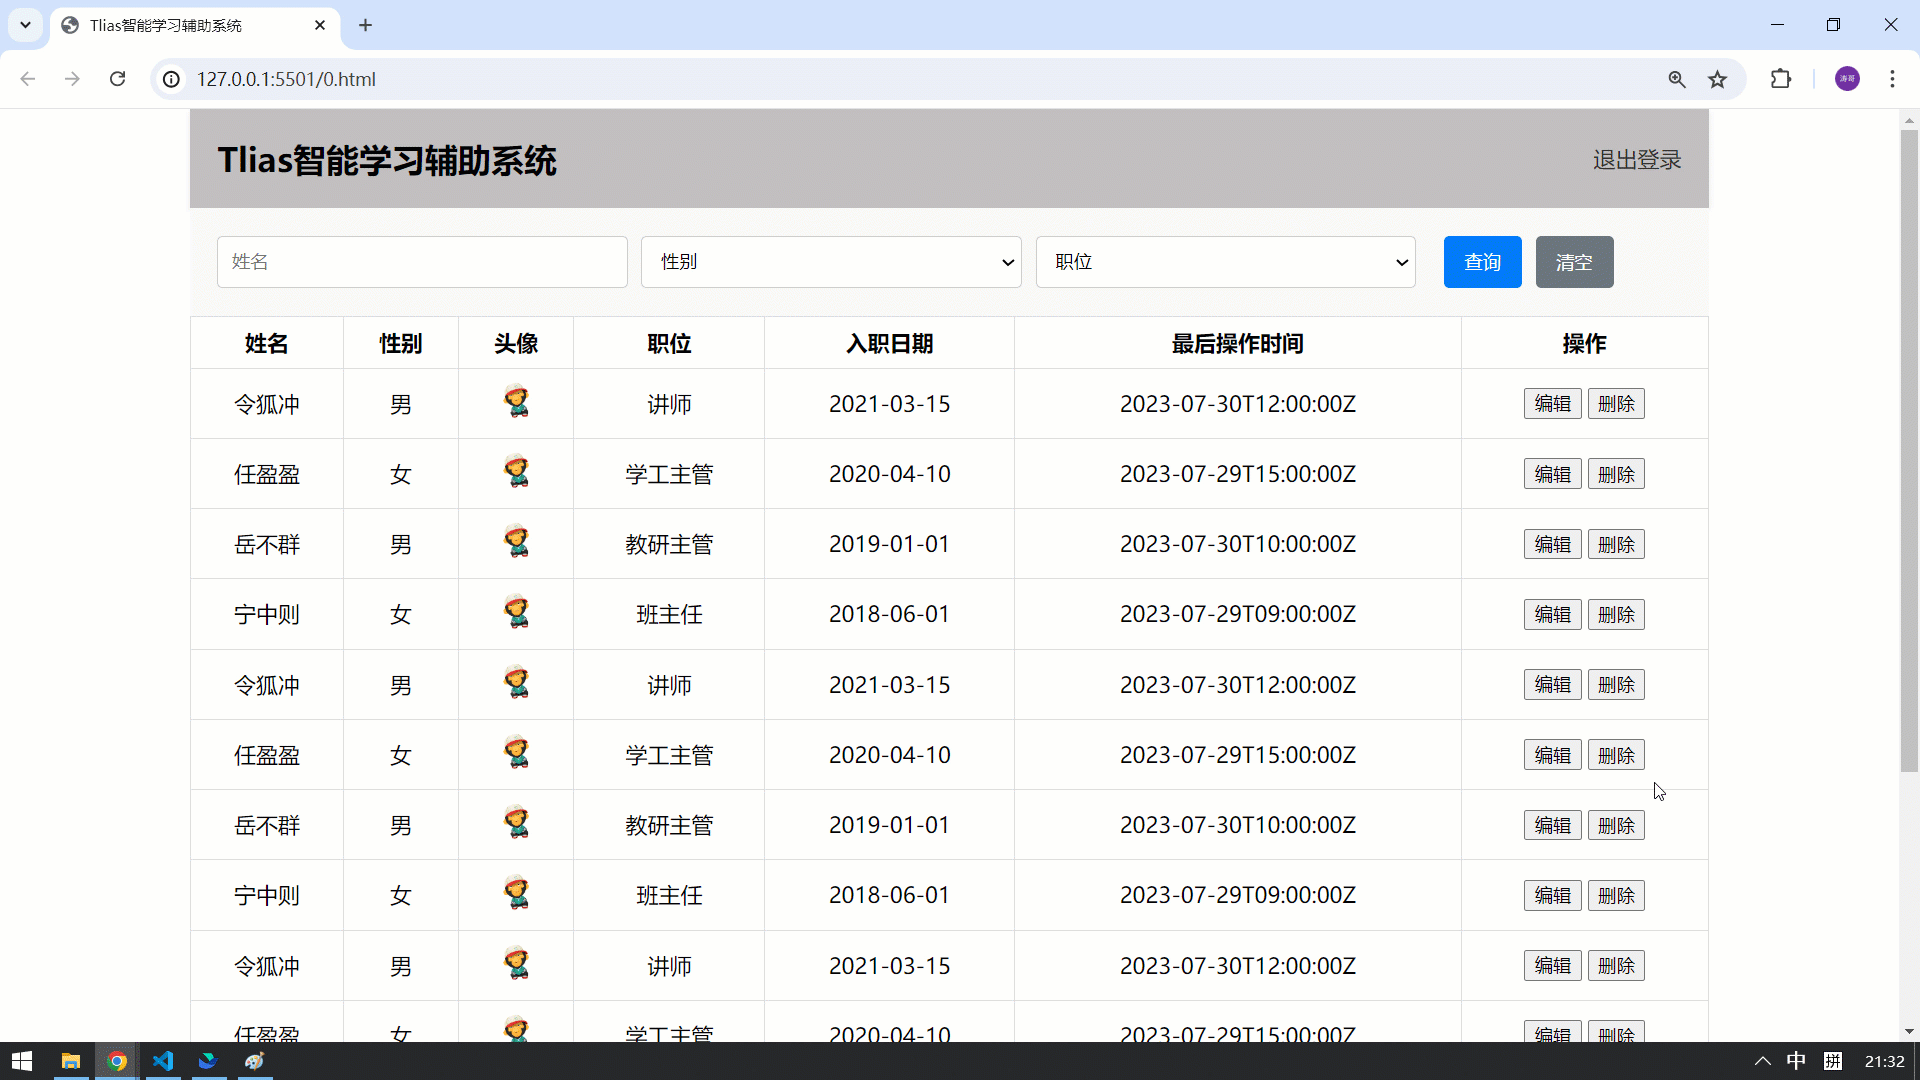

这个功能，我们就可以直接基于通义零码来帮我们实现了。

> 提示词（prompt）：
> 
> 通过js实现鼠标移入移出效果，鼠标移入，背景色为 &#35;f2e2e2，鼠标移出，背景色为 白色。

最终完整代码如下：

````html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Tlias智能学习辅助系统</title>
    <style>
      body {
        margin: 0;
      }

      /* 顶栏样式 */
      .header {
        display: flex;
        justify-content: space-between;
        align-items: center;
        background-color: #c2c0c0;
        padding: 20px 20px;
        box-shadow: 0 2px 5px rgba(0,0,0,0.1);
      }
      
      /* 加大加粗标题 */
      .header h1 {
        margin: 0;
        font-size: 24px;
        font-weight: bold;
      }

      /* 文本链接样式 */
      .header a {
        text-decoration: none;
        color: #333;
        font-size: 16px;
      }

      /* 搜索表单区域 */
      .search-form {
        display: flex;
        align-items: center;
        padding: 20px;
        background-color: #f9f9f9;
      }

      /* 表单控件样式 */
      .search-form input[type="text"], .search-form select {
        margin-right: 10px;
        padding: 10px 10px;
        border: 1px solid #ccc;
        border-radius: 4px;
        width: 26%;
      }

      /* 按钮样式 */
      .search-form button {
        padding: 10px 15px;
        margin-left: 10px;
        background-color: #007bff;
        color: white;
        border: none;
        border-radius: 4px;
        cursor: pointer;
      }

      /* 清空按钮样式 */
      .search-form button.clear {
        background-color: #6c757d;
      }

      .table {
         min-width: 100%; 
         border-collapse: collapse;
      }

      /* 设置表格单元格边框 */
      .table td, .table th { 
        border: 1px solid #ddd; 
        padding: 8px; 
        text-align: center;
      }
      
      .avatar { 
        width: 30px; 
        height: 30px; 
        object-fit: cover; 
        border-radius: 50%; 
      }

      /* 页脚版权区域 */
    .footer {
        background-color: #c2c0c0;
        color: white;
        text-align: center;
        padding: 10px 0;
        margin-top: 30px;
    }

    .footer .company-name {
        font-size: 1.1em;
        font-weight: bold;
    }

    .footer .copyright {
        font-size: 0.9em;
    }

    #container {
      width: 80%;
      margin: 0 auto;
    }
    </style>
</head>
<body>
    
  <div id="container">
    <!-- 顶栏 -->
    <div class="header">
      <h1>Tlias智能学习辅助系统</h1>
      <a href="#">退出登录</a>
    </div>

    <!-- 搜索表单区域 -->
    <form class="search-form" action="#" method="post">
      <input type="text" name="name" placeholder="姓名" />
      <select name="gender">
          <option value="">性别</option>
          <option value="1">男</option>
          <option value="2">女</option>
      </select>
      <select name="job">
          <option value="">职位</option>
          <option value="1">班主任</option>
          <option value="2">讲师</option>
          <option value="3">学工主管</option>
          <option value="4">教研主管</option>
          <option value="5">咨询师</option>
      </select>
      <button type="submit">查询</button>
      <button type="reset" class="clear">清空</button>
    </form>

    <table class="table table-striped table-bordered">
      <thead>
          <tr>
              <th>姓名</th>
              <th>性别</th>
              <th>头像</th>
              <th>职位</th>
              <th>入职日期</th>
              <th>最后操作时间</th>
              <th>操作</th>
          </tr>
      </thead>
      <tbody>
        <tr>
            <td>令狐冲</td>
            <td>男</td>
            <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="令狐冲" class="avatar"></td>
            <td>讲师</td>
            <td>2021-03-15</td>
            <td>2023-07-30T12:00:00Z</td>
            <td class="btn-group">
                <button class="edit">编辑</button>
                <button class="delete">删除</button>
            </td>
        </tr>
        <tr>
            <td>任盈盈</td>
            <td>女</td>
            <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="任盈盈" class="avatar"></td>
            <td>学工主管</td>
            <td>2020-04-10</td>
            <td>2023-07-29T15:00:00Z</td>
            <td class="btn-group">
                <button class="edit">编辑</button>
                <button class="delete">删除</button>
            </td>
        </tr>
        <tr>
            <td>岳不群</td>
            <td>男</td>
            <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="岳不群" class="avatar"></td>
            <td>教研主管</td>
            <td>2019-01-01</td>
            <td>2023-07-30T10:00:00Z</td>
            <td class="btn-group">
                <button class="edit">编辑</button>
                <button class="delete">删除</button>
            </td>
        </tr>
        <tr>
            <td>宁中则</td>
            <td>女</td>
            <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="宁中则" class="avatar"></td>
            <td>班主任</td>
            <td>2018-06-01</td>
            <td>2023-07-29T09:00:00Z</td>
            <td class="btn-group">
                <button class="edit">编辑</button>
                <button class="delete">删除</button>
            </td>
        </tr>
        <tr>
          <td>令狐冲</td>
          <td>男</td>
          <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="令狐冲" class="avatar"></td>
          <td>讲师</td>
          <td>2021-03-15</td>
          <td>2023-07-30T12:00:00Z</td>
          <td class="btn-group">
              <button class="edit">编辑</button>
              <button class="delete">删除</button>
          </td>
        </tr>
        <tr>
            <td>任盈盈</td>
            <td>女</td>
            <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="任盈盈" class="avatar"></td>
            <td>学工主管</td>
            <td>2020-04-10</td>
            <td>2023-07-29T15:00:00Z</td>
            <td class="btn-group">
                <button class="edit">编辑</button>
                <button class="delete">删除</button>
            </td>
        </tr>
        <tr>
            <td>岳不群</td>
            <td>男</td>
            <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="岳不群" class="avatar"></td>
            <td>教研主管</td>
            <td>2019-01-01</td>
            <td>2023-07-30T10:00:00Z</td>
            <td class="btn-group">
                <button class="edit">编辑</button>
                <button class="delete">删除</button>
            </td>
        </tr>
        <tr>
            <td>宁中则</td>
            <td>女</td>
            <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="宁中则" class="avatar"></td>
            <td>班主任</td>
            <td>2018-06-01</td>
            <td>2023-07-29T09:00:00Z</td>
            <td class="btn-group">
                <button class="edit">编辑</button>
                <button class="delete">删除</button>
            </td>
        </tr>
        <tr>
          <td>令狐冲</td>
          <td>男</td>
          <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="令狐冲" class="avatar"></td>
          <td>讲师</td>
          <td>2021-03-15</td>
          <td>2023-07-30T12:00:00Z</td>
          <td class="btn-group">
              <button class="edit">编辑</button>
              <button class="delete">删除</button>
          </td>
        </tr>
        <tr>
            <td>任盈盈</td>
            <td>女</td>
            <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="任盈盈" class="avatar"></td>
            <td>学工主管</td>
            <td>2020-04-10</td>
            <td>2023-07-29T15:00:00Z</td>
            <td class="btn-group">
                <button class="edit">编辑</button>
                <button class="delete">删除</button>
            </td>
        </tr>
        <tr>
            <td>岳不群</td>
            <td>男</td>
            <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="岳不群" class="avatar"></td>
            <td>教研主管</td>
            <td>2019-01-01</td>
            <td>2023-07-30T10:00:00Z</td>
            <td class="btn-group">
                <button class="edit">编辑</button>
                <button class="delete">删除</button>
            </td>
        </tr>
        <tr>
            <td>宁中则</td>
            <td>女</td>
            <td><img src="https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg" alt="宁中则" class="avatar"></td>
            <td>班主任</td>
            <td>2018-06-01</td>
            <td>2023-07-29T09:00:00Z</td>
            <td class="btn-group">
                <button class="edit">编辑</button>
                <button class="delete">删除</button>
            </td>
        </tr>
      </tbody>
    </table>

    <!-- 页脚版权区域 -->
    <footer class="footer">
      <p class="company-name">江苏传智播客教育科技股份有限公司</p>
      <p class="copyright">版权所有 Copyright 2006-2024 All Rights Reserved</p>
    </footer>

    <script>
      //点击列表中每一条记录后面的删除按钮，弹出一个提示框，提示：您是否要删除这条记录？ 如果确定，则移出这条记录
      const deleteButtons = document.querySelectorAll('.delete');
      for (let i = 0; i < deleteButtons.length; i++) {
        deleteButtons[i].addEventListener('click', function () {
          if (confirm('您是否要删除这条记录？')) {
            //点击确定按钮，删除当前记录
            this.parentNode.parentNode.remove();
          }
        });
      }
      
      //通过js实现鼠标移入移出效果，鼠标移入，背景色为 #f2e2e2，鼠标移出，背景色为 白色。
      const trs = document.querySelectorAll('tr');
      for (let i = 1; i < trs.length; i++) {
        trs[i].addEventListener('mouseenter', function () {
          this.style.backgroundColor = '#f2e2e2';
        });
        trs[i].addEventListener('mouseleave', function () {
          this.style.backgroundColor = '#fff';
        });
      }
    </script>
    
  </div>
    
</body>
</html>
````

> **补充：**删除按钮位于 `td` 内，`this.parentNode.parentNode` 从按钮依次找到 `td`、`tr`，再移除该行。这里用普通 `function`，事件触发时 `this` 指向当前按钮；不能不加修改就换成箭头函数。也可以用 `event.currentTarget.closest('tr')` 找到最近的行，减少对嵌套层级的依赖。
>
> `confirm` 返回 `true` 才删除，取消则不动。删除只改变当前页面 DOM，没有修改服务器数据，刷新会恢复。`mouseenter / mouseleave` 用来控制整行移入、移出，并通过跳过第 0 行来排除表头。


### 3.4 常见事件

上面案例中使用到了事件 <code>click</code>、<code>mouseenter</code>、<code>mouseleave</code>，那都有哪些事件类型供我们使用呢？下面就给大家列举一些比较常用的事件属性: 

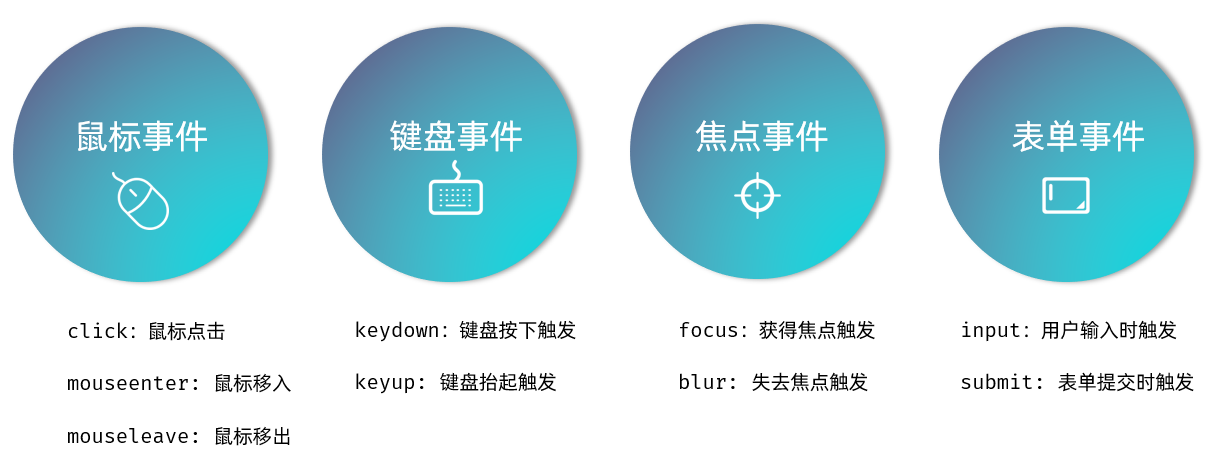

**配图文字转写：常见事件。**

| 分类 | 事件 | 触发时机 |
| --- | --- | --- |
| 鼠标 | `click` | 鼠标点击 |
| 鼠标 | `mouseenter / mouseleave` | 鼠标进入 / 离开元素 |
| 键盘 | `keydown / keyup` | 按键按下 / 抬起 |
| 焦点 | `focus / blur` | 获得 / 失去焦点 |
| 表单 | `input` | 用户输入改变内容 |
| 表单 | `submit` | 表单提交 |


示例演示：

````html
<!DOCTYPE html>
<html lang="en">

<head>
    <meta charset="UTF-8">
    <meta http-equiv="X-UA-Compatible" content="IE=edge">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>JS-事件-常见事件</title>
</head>

<body>
    <form action="" style="text-align: center;">
        <input type="text" name="username" id="username">
        <input type="text" name="age" id="age">
        <input id="b1" type="submit" value="提交">
        <input id="b2" type="button" value="单击事件">
    </form>

    <br><br><br>

    <table width="800px" border="1" cellspacing="0" align="center">
        <tr>
            <th>学号</th>
            <th>姓名</th>
            <th>分数</th>
            <th>评语</th>
        </tr>
        <tr align="center">
            <td>001</td>
            <td>张三</td>
            <td>90</td>
            <td>很优秀</td>
        </tr>
        <tr align="center" id="last">
            <td>002</td>
            <td>李四</td>
            <td>92</td>
            <td>优秀</td>
        </tr>
    </table>
    
    <script>
        //click: 鼠标点击事件
        document.querySelector('#b2').addEventListener('click', () => {
            console.log("我被点击了...");
        })
        
        //mouseenter: 鼠标移入
        document.querySelector('#last').addEventListener('mouseenter', () => {
            console.log("鼠标移入了...");
        })

        //mouseleave: 鼠标移出
        document.querySelector('#last').addEventListener('mouseleave', () => {
            console.log("鼠标移出了...");
        })

        //keydown: 某个键盘的键被按下
        document.querySelector('#username').addEventListener('keydown', () => {
            console.log("键盘被按下了...");
        })

        //keydown: 某个键盘的键被抬起
        document.querySelector('#username').addEventListener('keyup', () => {
            console.log("键盘被抬起了...");
        })

        //blur: 失去焦点事件
        document.querySelector('#age').addEventListener('blur', () => {
            console.log("失去焦点...");
        })

        //focus: 元素获得焦点
        document.querySelector('#age').addEventListener('focus', () => {
            console.log("获得焦点...");
        })

        //input: 用户输入时触发
        document.querySelector('#age').addEventListener('input', () => {
            console.log("用户输入时触发...");
        })

        //submit: 提交表单事件
        document.querySelector('form').addEventListener('submit', () => {
            alert("表单被提交了...");
        })
    </script>
</body>

</html>
````

> **勘误：**抬起按键对应 `keyup`，示例那一行注释误写为 `keydown`，实际绑定的事件名称正确。`submit` 监听器仅弹出提示，仍会继续浏览器默认提交；若要改成 JavaScript 处理，可在回调参数中接收 `event` 并调用 `event.preventDefault()`。

前面两天，我们已经学习了前端网页开发的三剑客：HTML、CSS、JS。那通过这三种技术呢，我们就可以开发出一个网页程序了，但是如果我们使用原生的JS来处理界面的交互行为，开发效率呢，是比较低的。而在现在的企业项目开发中，一般会借助于Vue这样的js框架来简化操作、提高开发效率。 那么我们今天接下来呢，就来学习Vue这个框架。


## 4 Vue介绍


### 4.1 概述

Vue（读音 /vjuː /, 类似于 view），是一款用于<strong>构建用户界面</strong>的<strong>渐进式</strong>的JavaScript<strong>框架</strong>（官方网站：https://cn.vuejs.org）。

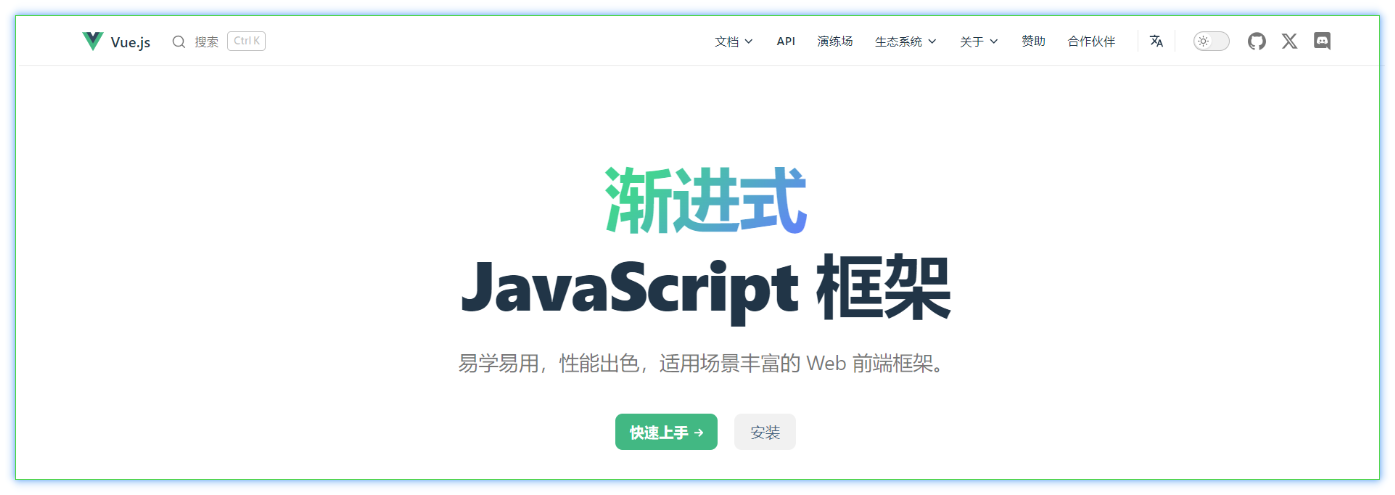

在上面的这句话中呢，出现了三个词，分别是：<strong>构建用户界面、渐进式、框架</strong>。

<strong>1). 构建用户界面</strong>

构建用户界面是指，在Vue中，可以基于数据渲染出用户看到的界面。 那这句话什么意思呢？我们来举一个例子，比如将来服务器端返回给前端的原始数据呢，就是如下这个样子：

````json
userList: [
    {"id": 1, "name": "谢逊", "image": "1.jpg", "gender": 1, "job": "班主任"},
    {"id": 2, "name": "韦一笑", "image": "2.jpg", "gender": 1, "job": "班主任"}
]
````

> **勘误：**这段是对象属性片段，不是独立 JSON 文档。真正传输为 JSON 时，需要包在对象里并给属性名加双引号：

```json
{
  "userList": [
    {"id": 1, "name": "谢逊", "image": "1.jpg", "gender": 1, "job": "班主任"},
    {"id": 2, "name": "韦一笑", "image": "2.jpg", "gender": 1, "job": "班主任"}
  ]
}
```

而上面的这些原始数据，用户是看不懂的。 而我们开发人员呢，可以使用Vue中提供的操作，将原始数据遍历、解析出来，从而渲染呈现出用户所能看懂的界面，如下所示：

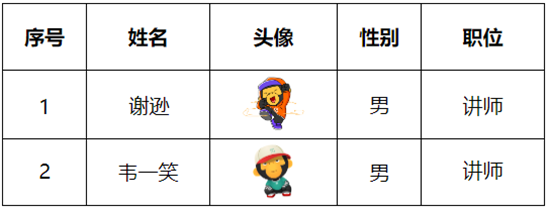

那这个过程呢，就是基于数据渲染出用户看到的界面，也就是所谓的 构建用户界面。

<strong>2). </strong><strong>渐进式</strong>

渐进式中的渐进呢，字面意思就是 "循序渐进"。Vue生态中的语法呢是非常多的，比如声明式渲染、组件系统、客户端路由（VueRouter）、状态管理（Vuex、Pinia）、构建工具（Webpack、Vite）等等。

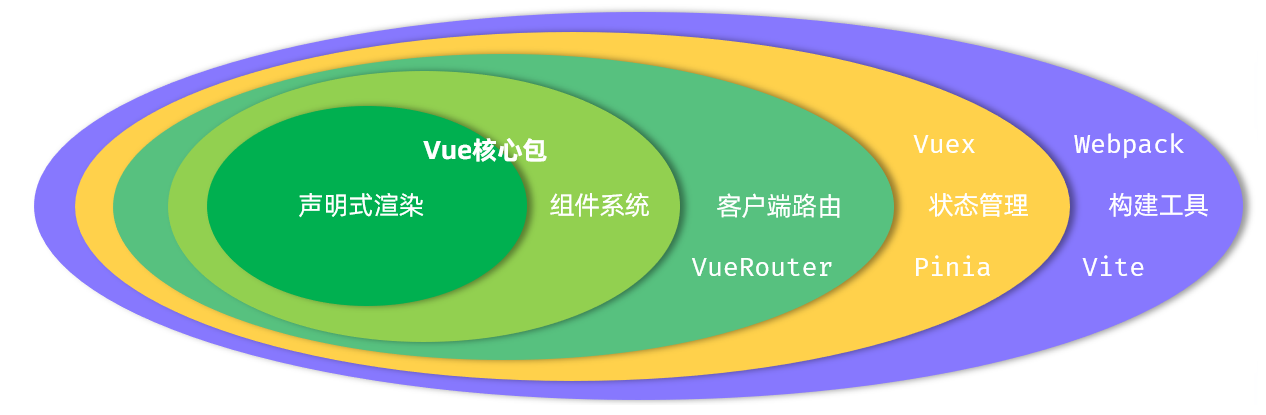

所谓渐进，指的是我们使用Vue框架呢，我们不需要把所有的组件、语法全部学习完毕才可以使用Vue。 而是，我们学习一点就可以使用一点了，比如：

- 我们学习了声明式渲染，我们就可以使用Vue来构建用户界面了。 
- 我们再学习了组件系统，我们就可以使用Vue中的组件，从而来复用了。
- 我们再学习了路由VueRouter，就可以使用Vue中的中的路由功能了。

也就是说，并不需要全部学习完毕就可以直接使用Vue进行开发，简化操作、提高效率了。 Vue是一个框架，但其实也是一个生态。

那由此呢，也就引出了Vue中两种常见的开发模式：

- 基于Vue提供的核心包，完成项目局部模块的改造了。
- 基于Vue提供的核心包、插件进行工程化开发，也就是做整站开发。

那上面的这两种Vue的使用形式，我们都会学习，今天我们先来学习第一种方式，就是使用Vue来完成局部模块改造。

<strong>3).</strong><strong> 框架</strong>

- 框架：就是一套完整的项目解决方案，用于快速构建项目 。这是我们接触的第一个框架，那在我们后面的学习中，我们还会学习很多的java语言中的框架，那通过这些框架呢，就可以来快速开发java项目，提高开发效率。
- 优点：大大提升前端项目的开发效率 。
- 缺点：需要理解记忆框架的使用规则 。（参照官网）

好，那我们知道了什么是Vue之后，接下来，就要正式进入Vue的学习，我们今天主要讲解以下几个方面：

1. Vue快速入门
2. Vue常用指令
3. Ajax
4. Vue生命周期


### 4.2 入门程序


#### 4.2.1 需求

在入门程序中，最终我们需要将准备的数据 message 的值，基于Vue渲染展示在页面中，最终呈现的形式如下：

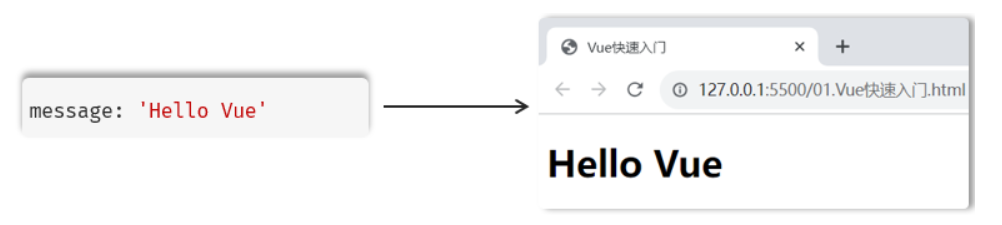


#### 4.2.2 步骤

<strong>1). 准备工作：</strong>

- 准备一个html文件，并在其中引入Vue模块 （参考官方文档，复制过来即可）【注意：模块化的js，引入时，需要设置 <code>type="module"</code>】
- 创建Vue程序的应用实例，控制视图的元素
- 准备元素（div），交给Vue控制

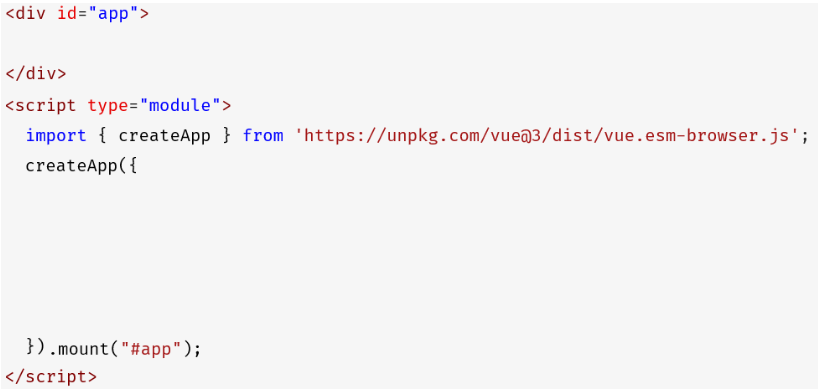

这是三步准备工作，是我们使用Vue时，都需要做的，是固定步骤。 这样我们就搭建好了一个基本的Vue的结构了。

<strong>2). 数据驱动视图：</strong>

- 准备数据。 在创建Vue应用实例的时候，传入了一个js对象，在这个js对象中，我们要定义一个data方法，这个data方法的返回值就是Vue中的数据。
- 通过插值表达式渲染页面。 插值表达式的写法：{{...}}

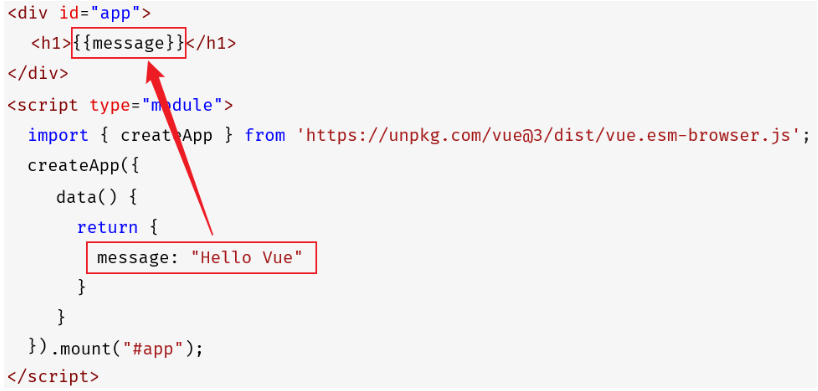


#### 4.2.3 实现

````html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Vue-快速入门</title>
</head>
<body>
  <div id="app">
    {{message}}
  </div>
  
  <script type="module">
    import { createApp } from 'https://unpkg.com/vue@3/dist/vue.esm-browser.js'
    createApp({
      data(){
        return {
          message: 'Hello Vue'
        }
      }
    }).mount('#app')
  </script>
</body>
</html>
````

> **运行补充：**保存为 `.html`，用 VS Code 的 Live Server 打开。浏览器要能获取 Vue 模块；若页面一直显示 `{{message}}`，先看控制台与网络面板，检查模块地址、`type="module"`、`#app` 和脚本错误。
>
> 学习固定版本时可把导入地址换为 `https://unpkg.com/vue@3.5.43/dist/vue.esm-browser.js`；这也是本笔记验证所用的版本。若下载了同一构建文件放入项目的 `js` 目录，改用 `import { createApp } from './js/vue.esm-browser.js'`，仍通过本地 HTTP 服务访问。

在上述入门程序编写时，需要注意这么几点：

- Vue中定义数据，必须通过data方法来定义，data方法返回值是一个对象，在这个对象中定义数据。

> **范围说明：**这里针对本章使用的选项式 API。Vue 3 也支持组合式 API，并不是所有 Vue 代码都必须有 `data()`。当前写法下，`data()` 返回对象中的属性可以在模板中直接使用，在方法中通过 `this.属性名` 访问。
- 插值表达式中编写的变量，一定是Vue中定义的数据，如果插值表达式中编写了一个变量，但是在Vue中未定义，将会报错 。

> **补充：**访问未定义的简单属性，开发版通常会警告并显示空内容；继续读取其子属性则可能抛出错误。不要只看页面是否空白，控制台信息也是检查依据。
- Vue应用实例接管的区域是 '&#35;app'，超出这个范围，就不受Vue控制了，所以vue的插值表达式，一定写在 <code>&lt;div id="app"&gt;...&lt;/div&gt;</code> 的里面 。


## 5 Vue指令


### 5.1 概述

<strong>指令：</strong>指的是HTML 标签上带有 v- 前缀的特殊属性，不同指令具有不同含义，可以实现不同的功能 。例如：v-if，v-for…

<strong>形式：</strong>

````html
<p v-xxx="....">.....</p>
````

<strong>常见指令：</strong>

| 指令 | 作用 |
| --- | --- |
| v-for | 列表渲染，遍历容器的元素或者对象的属性 |
| v-bind | 为HTML标签绑定属性值，如设置 href , css样式等 |
| v-if/v-else-if/v-else | 条件性的渲染某元素，判定为true时渲染,否则不渲染 |
| v-show | 根据条件展示某元素，区别在于切换的是display属性的值 |
| v-model | 在表单元素上创建双向数据绑定 |
| v-on | 为HTML标签绑定事件 |

> **补充：**`{{ … }}` 用于文本插值，`v-bind` 用于属性绑定，`v-on` 用于事件绑定，`v-model` 用于表单双向绑定。它们只在 Vue 挂载并接管的模板区域内生效。本章采用 Vue 3 的选项式 API。


### 5.2 案例


#### 5.2.1 基本实现

需求：员工列表数据渲染展示 。（备注：基础代码在资料中，已经提供，导入VsCode即可）

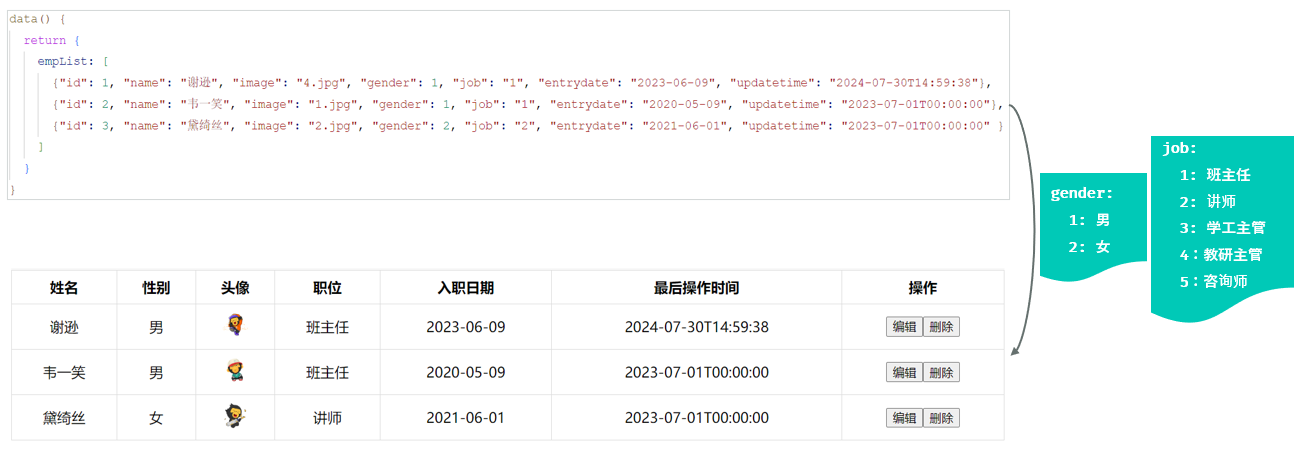

> AI提示词（prompt）：
> 
> 基于Vue3中提供的指令，渲染展示employees中的数据，并展示在页面上；
> 
> - 性别gender为1展示为男，性别为2展示为女；
> - 职位job为1展示为班主任，职位为2展示为讲师，职位为3展示为学工主管，职位为4展示为教研主管，职位为5展示为咨询师； 
> - 其他的属性直接展示；
> 
> 页面的内容如下：
> 
> .....

生成后的代码如下：

````html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Tlias智能学习辅助系统</title>
    <style>
      body {
        margin: 0;
      }

      /* 顶栏样式 */
      .header {
        display: flex;
        justify-content: space-between;
        align-items: center;
        background-color: #c2c0c0;
        padding: 20px 20px;
        box-shadow: 0 2px 5px rgba(0,0,0,0.1);
      }
      
      /* 加大加粗标题 */
      .header h1 {
        margin: 0;
        font-size: 24px;
        font-weight: bold;
      }

      /* 文本链接样式 */
      .header a {
        text-decoration: none;
        color: #333;
        font-size: 16px;
      }

      /* 搜索表单区域 */
      .search-form {
        display: flex;
        align-items: center;
        padding: 20px;
        background-color: #f9f9f9;
      }

      /* 表单控件样式 */
      .search-form input[type="text"], .search-form select {
        margin-right: 10px;
        padding: 10px 10px;
        border: 1px solid #ccc;
        border-radius: 4px;
        width: 26%;
      }

      /* 按钮样式 */
      .search-form button {
        padding: 10px 15px;
        margin-left: 10px;
        background-color: #007bff;
        color: white;
        border: none;
        border-radius: 4px;
        cursor: pointer;
      }

      /* 清空按钮样式 */
      .search-form button.clear {
        background-color: #6c757d;
      }

      .table {
         min-width: 100%; 
         border-collapse: collapse;
      }

      /* 设置表格单元格边框 */
      .table td, .table th { 
        border: 1px solid #ddd; 
        padding: 8px; 
        text-align: center;
      }
      
      .avatar { 
        width: 30px; 
        height: 30px; 
        object-fit: cover; 
        border-radius: 50%; 
      }

      /* 页脚版权区域 */
    .footer {
        background-color: #c2c0c0;
        color: white;
        text-align: center;
        padding: 10px 0;
        margin-top: 30px;
    }

    .footer .company-name {
        font-size: 1.1em;
        font-weight: bold;
    }

    .footer .copyright {
        font-size: 0.9em;
    }

    #container {
      width: 80%;
      margin: 0 auto;
    }
    </style>
</head>
<body>
    
  <div id="container">
    <!-- 顶栏 -->
    <div class="header">
      <h1>Tlias智能学习辅助系统</h1>
      <a href="#">退出登录</a>
    </div>

    <!-- 搜索表单区域 -->
    <form class="search-form" action="#" method="post">
      <input type="text" name="name" placeholder="姓名" />
      <select name="gender">
          <option value="">性别</option>
          <option value="1">男</option>
          <option value="2">女</option>
      </select>
      <select name="job">
          <option value="">职位</option>
          <option value="1">班主任</option>
          <option value="2">讲师</option>
          <option value="3">学工主管</option>
          <option value="4">教研主管</option>
          <option value="5">咨询师</option>
      </select>
      <button type="submit">查询</button>
      <button type="reset" class="clear">清空</button>
    </form>

    <table class="table table-striped table-bordered">
      <thead>
          <tr>
              <th>姓名</th>
              <th>性别</th>
              <th>头像</th>
              <th>职位</th>
              <th>入职日期</th>
              <th>最后操作时间</th>
              <th>操作</th>
          </tr>
      </thead>
      <tbody>
        <tr v-for="(emp, index) in empList" :key="index">
          <td>{{ emp.name }}</td>
          <td>{{ emp.gender === 1 ? '男' : '女' }}</td>
          <td><img :src="emp.image" alt="{{ emp.name }}" class="avatar"></td>
          <td>{{ emp.job === '1' ? '班主任' : (emp.job === '2' ? '讲师' : (emp.job === '3' ? '学工主管' : (emp.job === '4' ? '教研主管' : (emp.job === '5' ? '咨询师' : '未知')))) }}</td>
          <td>{{ emp.entrydate }}</td>
          <td>{{ emp.updatetime }}</td>
          <td class="btn-group">
            <button class="edit">编辑</button>
            <button class="delete">删除</button>
          </td>
        </tr>
      </tbody>
    </table>

    <!-- 页脚版权区域 -->
    <footer class="footer">
      <p class="company-name">江苏传智播客教育科技股份有限公司</p>
      <p class="copyright">版权所有 Copyright 2006-2024 All Rights Reserved</p>
    </footer>

    <script type="module">
      import { createApp } from 'https://unpkg.com/vue@3/dist/vue.esm-browser.js'
      createApp({
        data() {
          return {
            empList: [
              { "id": 1,
                "name": "谢逊",
                "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/4.jpg",
                "gender": 1,
                "job": "1",
                "entrydate": "2023-06-09",
                "updatetime": "2024-07-30T14:59:38"
              },
              {
                "id": 2,
                "name": "韦一笑",
                "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg",
                "gender": 1,
                "job": "1",
                "entrydate": "2020-05-09",
                "updatetime": "2023-07-01T00:00:00"
              },
              {
                "id": 3,
                "name": "黛绮丝",
                "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/2.jpg",
                "gender": 2,
                "job": "2",
                "entrydate": "2021-06-01",
                "updatetime": "2023-07-01T00:00:00"
              }
            ]
          }
        }
      }).mount('#container')
    </script>

  </div>

</body>
</html>
````

> **勘误：**Vue 不在普通 HTML 属性值里解析双大括号，`alt="{{ emp.name }}"` 应改为 `:alt="emp.name"`。原案例多处使用 `:key="index"`；本例已有唯一 `id`，跟练时改为 `:key="emp.id"`，让列表身份与员工对应。

最终页面展示效果：

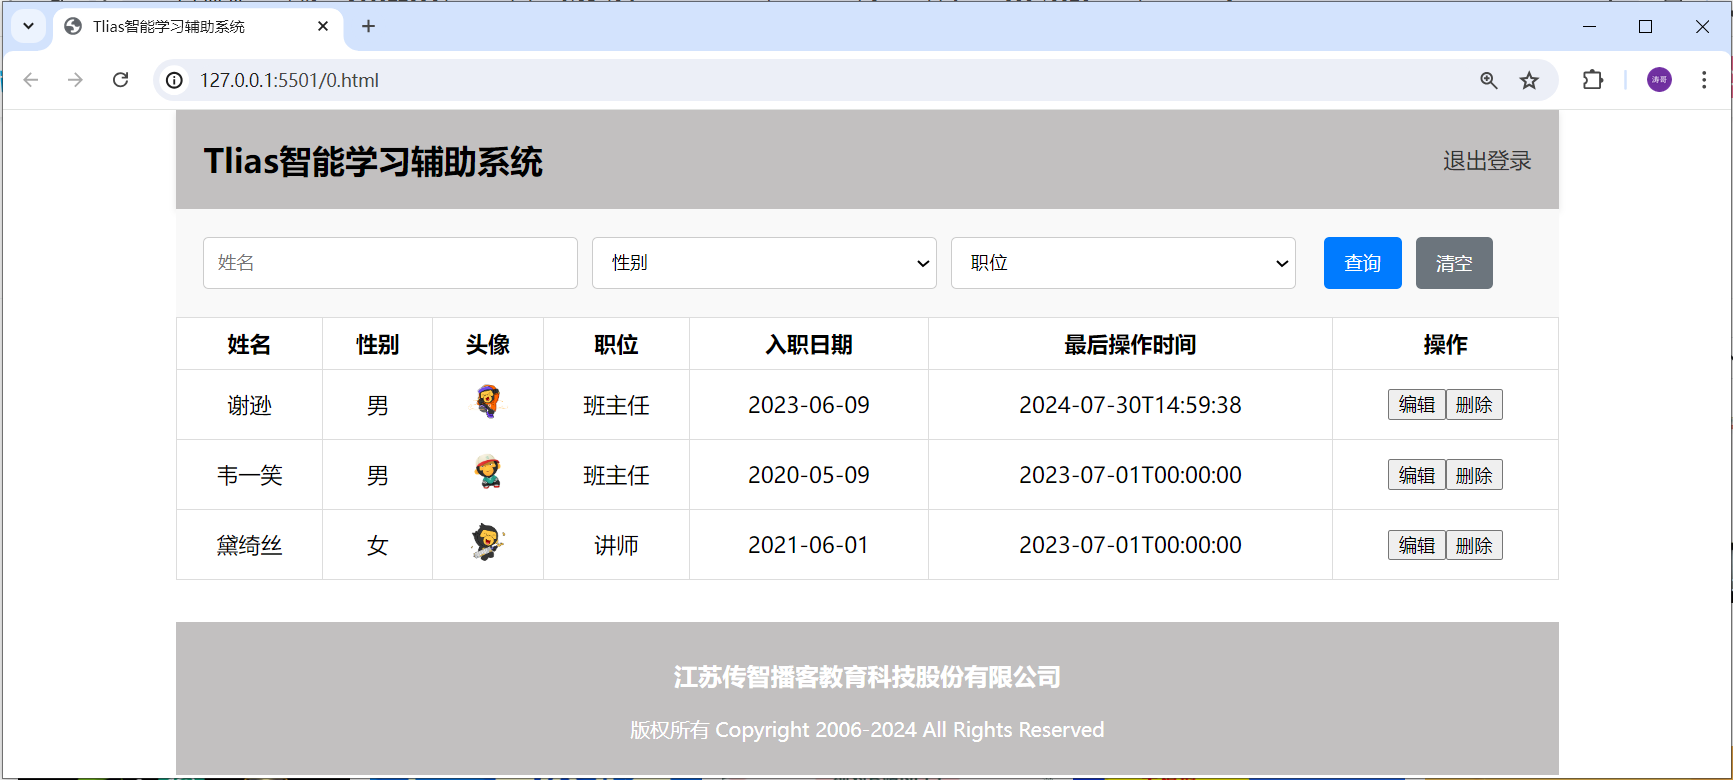

那我们看到，通过AI生成的代码，已经实现了员工列表数据渲染的功能。 而这里面呢，就用到了Vue中提供的指令和插值表达式。 那接下来，我们就来详细剖析一下Vue中指令的用法。


#### 5.2.2 指令详解

##### 5.2.2.1 v-for

<strong>作用：</strong>列表渲染，遍历容器的元素或者对象的属性

<strong>语法：</strong><code>&lt;tr v-for="(item,index) in items" :key="item.id"&gt;{{item}}&lt;/tr&gt;</code>

<strong>参数：</strong>

- items 为遍历的数组
- item 为遍历出来的元素
- index 为索引/下标，从0开始 ；可以省略，省略index语法： <code>v-for = "item in items"</code>

<strong>key：</strong>

- 作用：给元素添加的唯一标识，便于vue进行列表项的正确排序复用，提升渲染性能
- 推荐使用id作为key（唯一），不推荐使用index作为key（会变化，不对应）

<strong>注意：遍历的数组，必须在data中定义； 要想让哪个标签循环展示多次，就在哪个标签上使用 v-for 指令。</strong>

##### 5.2.2.2 v-bind

> **补充：**`src="emp.image"` 表示字面地址“emp.image”，`:src="emp.image"` 才表示读取当前员工的图片字段。表达式中的 `emp` 来自当前 `v-for`，不是单独的全局变量。

作用：动态为HTML标签绑定属性值，如设置href，src，style样式等。

语法：<code>v-bind:属性名="属性值"</code> <code>&lt;img </code><code>v-bind:src="item.image"</code><code> width="30px"&gt;</code>

简化：<code>:属性名="属性值"</code> <code>&lt;img </code><code>:</code><code>src="item.image" width="30px"&gt;</code>

<strong>注意：v-bind 所绑定的数据，必须在data中定义/或基于data中定义的数据而来。</strong>

##### 5.2.2.3 v-if & v-show

<strong>作用：</strong>这两类指令，都是用来控制元素的显示与隐藏的

<strong>v-if：</strong>

- 语法：v-if="表达式"，表达式值为 true，显示；false，隐藏
- 原理：基于条件判断，来控制创建或移除元素节点（条件渲染）
- 场景：要么显示，要么不显示，不频繁切换的场景
- 其它：可以配合 v-else-if / v-else 进行链式调用条件判断

<strong>示例：</strong>

````html
   <!-- 基于v-if/v-else-if/v-else指令来展示职位这一列 -->
  <td>
    <span v-if="emp.job === '1'">班主任</span>
    <span v-else-if="emp.job === '2'">讲师</span>
    <span v-else-if="emp.job === '3'">学工主管</span>
    <span v-else-if="emp.job === '4'">教研主管</span>
    <span v-else-if="emp.job === '5'">咨询师</span>
    <span v-else>其他</span>
  </td>
````

<strong>注意：v-else-if必须出现在v-if之后，可以出现多个； v-else 必须出现在v-if/v-else-if之后 。 </strong>

> **补充：**链式分支需要紧邻前一个 `v-if / v-else-if` 元素，不能在中间插入不相关元素。不要在同一个元素上同时写 `v-for` 与依赖循环变量的 `v-if`；本例把循环放在 `tr`、条件放在其内部 `span`，结构清楚。

通过浏览器的开发者工具，我们可以看到如果使用 <code>v-if</code> 指令来渲染展示，确实是根据条件判断，是否渲染这个元素节点，条件成立才会渲染。查看结果如下：

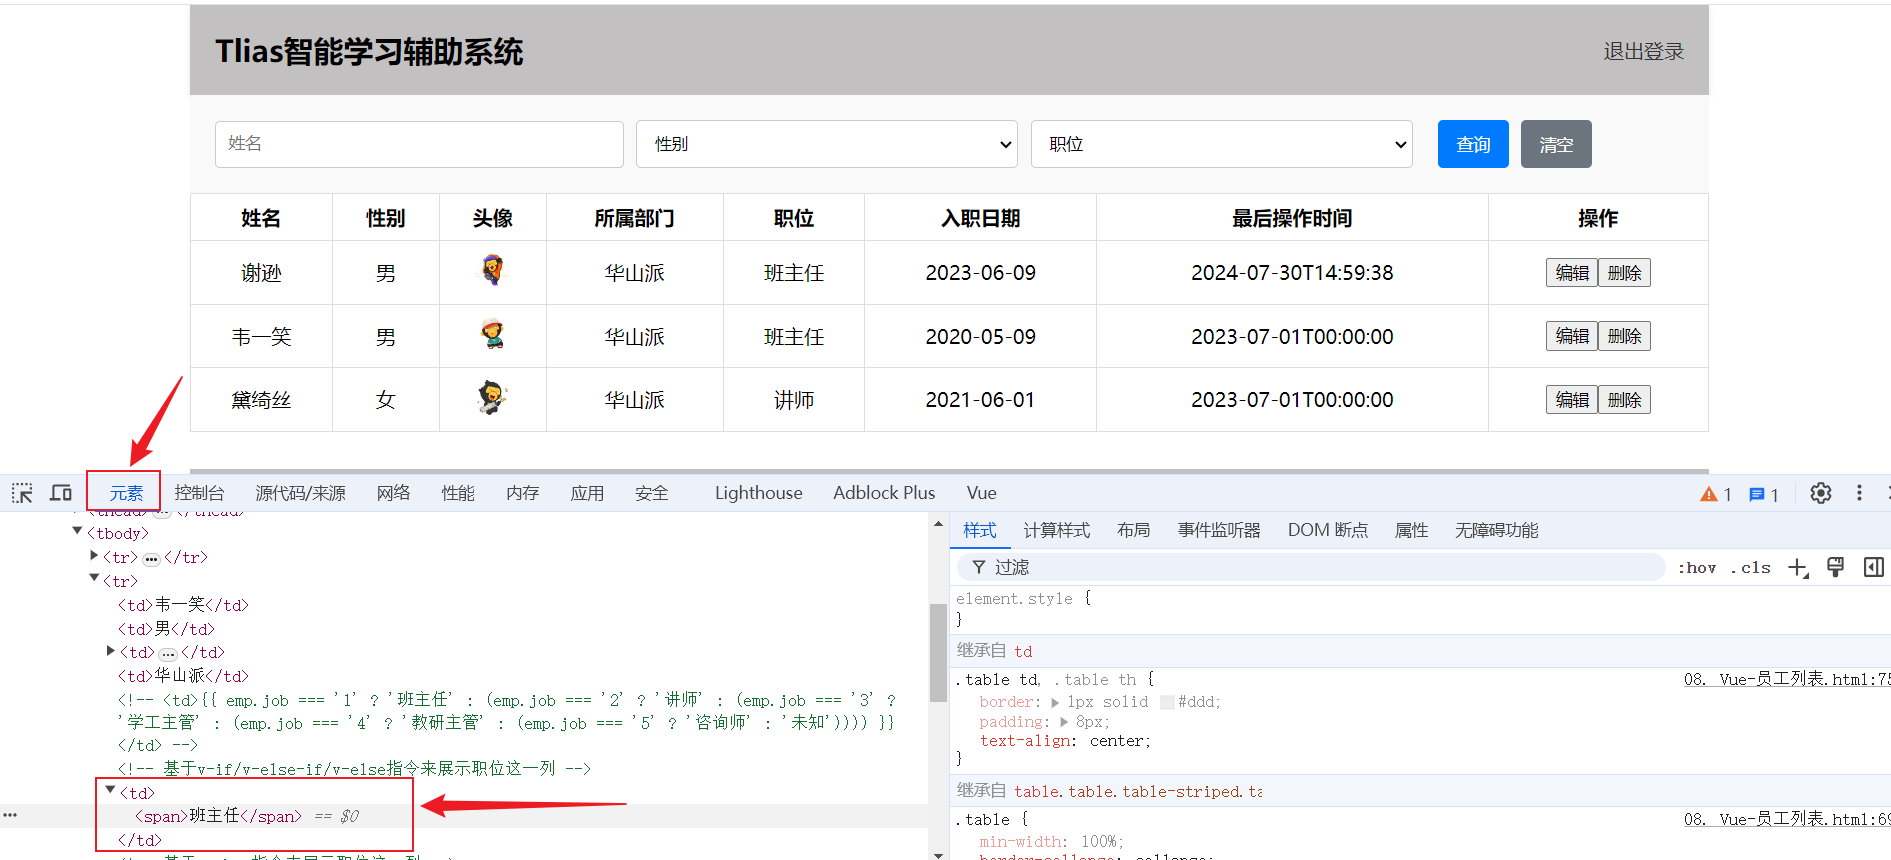

<strong>v-show：</strong>

- 语法：v-show="表达式"，表达式值为 true，显示；false，隐藏
- 原理：基于CSS样式display来控制显示与隐藏
- 场景：频繁切换显示隐藏的场景

<strong>示例：</strong>

````html
<!-- 基于v-show指令来展示职位这一列 -->
<td>
    <span v-show="emp.job === '1'">班主任</span>
    <span v-show="emp.job === '2'">讲师</span>
    <span v-show="emp.job === '3'">学工主管</span>
    <span v-show="emp.job === '4'">教研主管</span>
    <span v-show="emp.job === '5'">咨询师</span>
</td>
````

通过浏览器的开发者工具，我们可以看到如果使用 <code>v-show</code> 指令来渲染展示，所有元素都会渲染，只不过是通过控制display这个css样式，来决定元素是展示还是隐藏。查看结果如下：

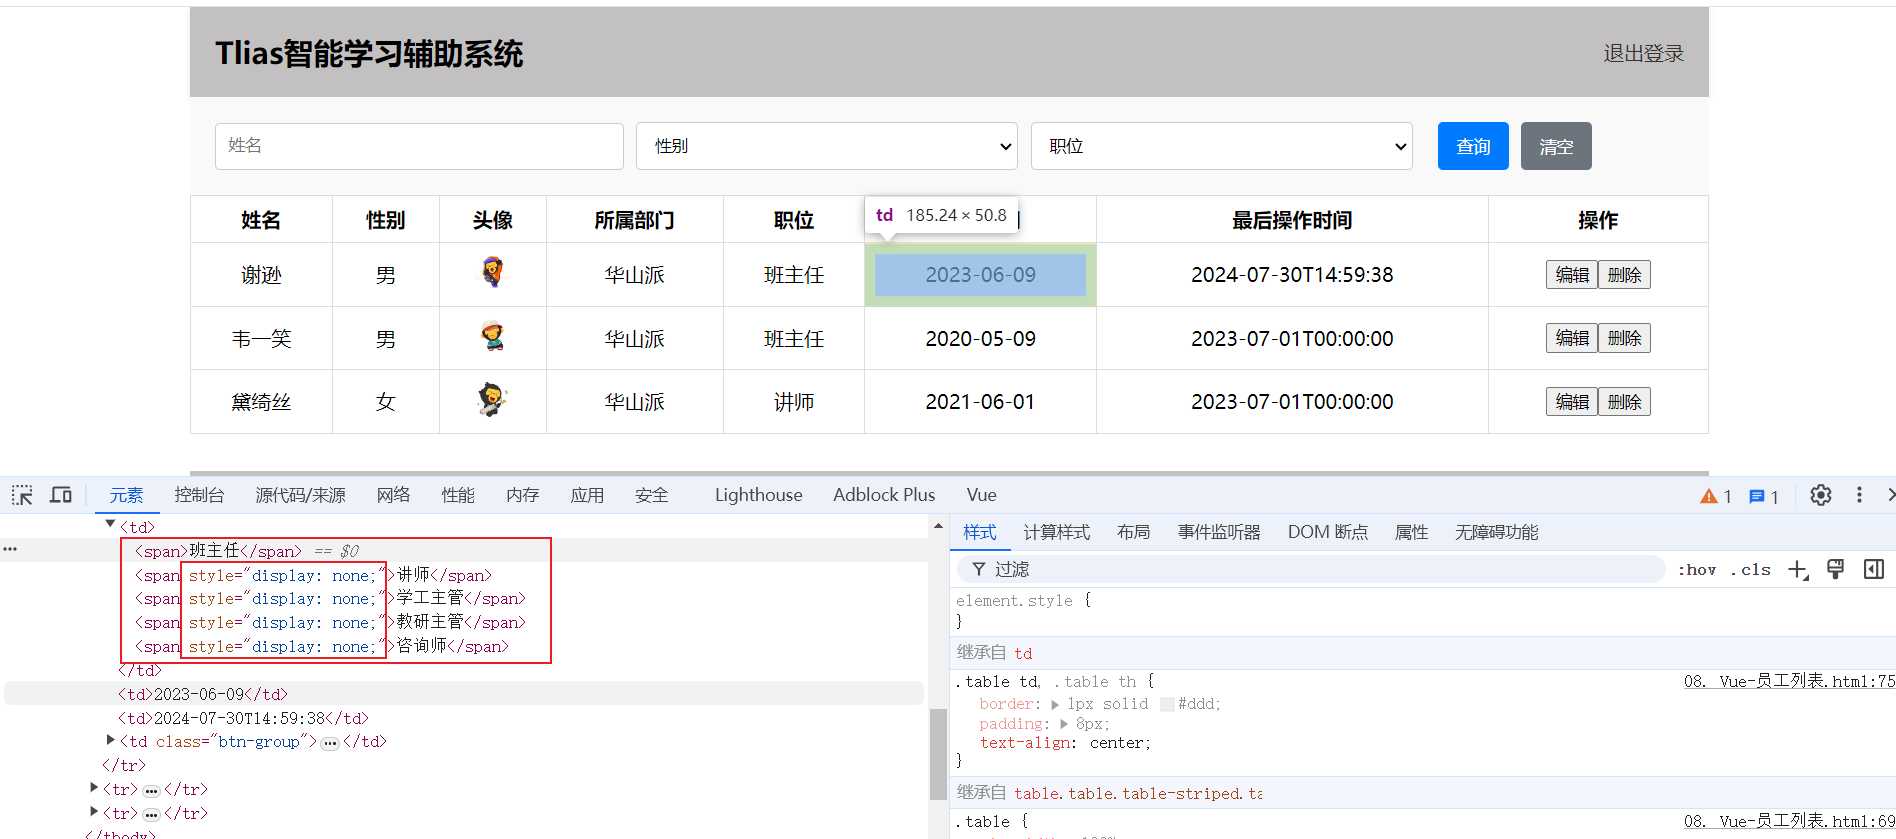

##### 5.2.2.4 v-model

- 作用：在表单元素上使用，<strong>双向数据绑定</strong>。可以方便的 <strong>获取</strong> 或 <strong>设置</strong> 表单项数据 
- 语法：<code>v-model="变量名"</code>
- 这里的双向数据绑定，是指 Vue中的数据变化，会影响视图中的数据展示 。 视图中的输入的数据变化，也会影响Vue的数据模型 。

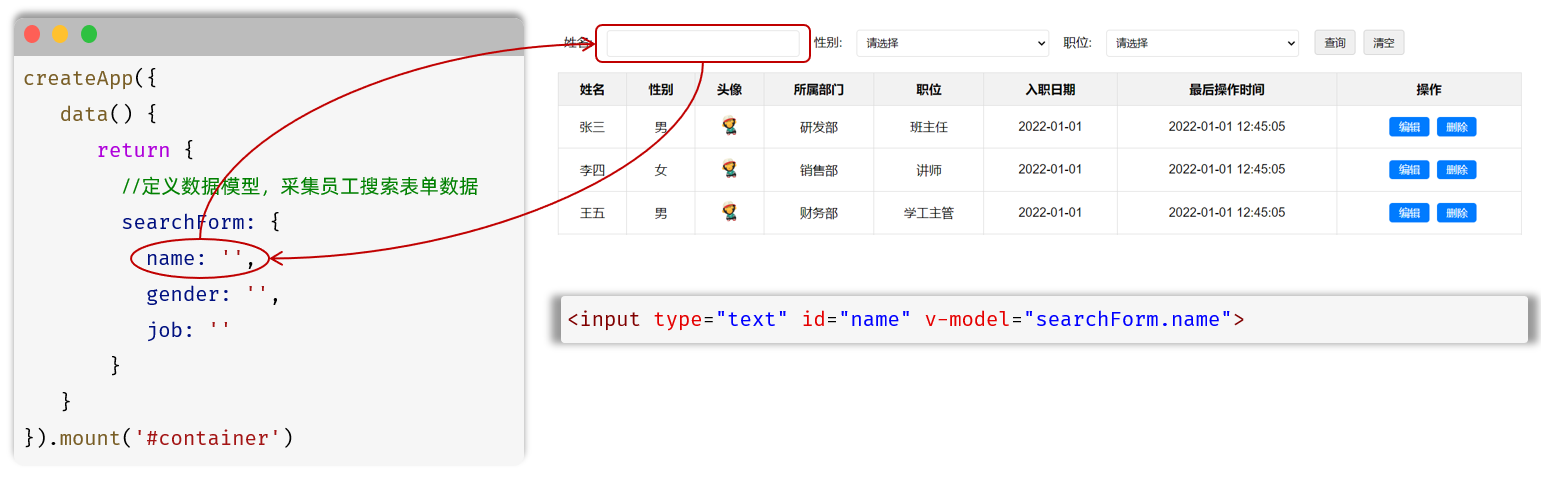

<strong>注意：v-model 中绑定的变量，必须在data中定义。</strong>

- 为员工列表案例的搜索栏的表单项，绑定数据：

````html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Tlias智能学习辅助系统</title>
    <style>
      body {
        margin: 0;
      }

      /* 顶栏样式 */
      .header {
        display: flex;
        justify-content: space-between;
        align-items: center;
        background-color: #c2c0c0;
        padding: 20px 20px;
        box-shadow: 0 2px 5px rgba(0,0,0,0.1);
      }
      
      /* 加大加粗标题 */
      .header h1 {
        margin: 0;
        font-size: 24px;
        font-weight: bold;
      }

      /* 文本链接样式 */
      .header a {
        text-decoration: none;
        color: #333;
        font-size: 16px;
      }

      /* 搜索表单区域 */
      .search-form {
        display: flex;
        align-items: center;
        padding: 20px;
        background-color: #f9f9f9;
      }

      /* 表单控件样式 */
      .search-form input[type="text"], .search-form select {
        margin-right: 10px;
        padding: 10px 10px;
        border: 1px solid #ccc;
        border-radius: 4px;
        width: 26%;
      }

      /* 按钮样式 */
      .search-form button {
        padding: 10px 15px;
        margin-left: 10px;
        background-color: #007bff;
        color: white;
        border: none;
        border-radius: 4px;
        cursor: pointer;
      }

      /* 清空按钮样式 */
      .search-form button.clear {
        background-color: #6c757d;
      }

      .table {
         min-width: 100%; 
         border-collapse: collapse;
      }

      /* 设置表格单元格边框 */
      .table td, .table th { 
        border: 1px solid #ddd; 
        padding: 8px; 
        text-align: center;
      }
      
      .avatar { 
        width: 30px; 
        height: 30px; 
        object-fit: cover; 
        border-radius: 50%; 
      }

      /* 页脚版权区域 */
    .footer {
        background-color: #c2c0c0;
        color: white;
        text-align: center;
        padding: 10px 0;
        margin-top: 30px;
    }

    .footer .company-name {
        font-size: 1.1em;
        font-weight: bold;
    }

    .footer .copyright {
        font-size: 0.9em;
    }

    #container {
      width: 80%;
      margin: 0 auto;
    }
    </style>
</head>
<body>
    
  <div id="container">
    <!-- 顶栏 -->
    <div class="header">
      <h1>Tlias智能学习辅助系统</h1>
      <a href="#">退出登录</a>
    </div>

    <!-- 搜索表单区域 -->
    <form class="search-form" action="#" method="post">
      <input type="text" name="name" placeholder="姓名" v-model="searchEmp.name" />
      <select name="gender" v-model="searchEmp.gender">
          <option value="">性别</option>
          <option value="1">男</option>
          <option value="2">女</option>
      </select>
      <select name="job" v-model="searchEmp.job">
          <option value="">职位</option>
          <option value="1">班主任</option>
          <option value="2">讲师</option>
          <option value="3">学工主管</option>
          <option value="4">教研主管</option>
          <option value="5">咨询师</option>
      </select>
      <button type="submit">查询</button>
      <button type="reset" class="clear">清空</button>
    </form>

    <table class="table table-striped table-bordered">
      <thead>
          <tr>
              <th>姓名</th>
              <th>性别</th>
              <th>头像</th>
              <th>职位</th>
              <th>入职日期</th>
              <th>最后操作时间</th>
              <th>操作</th>
          </tr>
      </thead>
      <tbody>
        <tr v-for="(emp, index) in empList" :key="index">
          <td>{{ emp.name }}</td>
          <td>{{ emp.gender === 1 ? '男' : '女' }}</td>
          <td><img :src="emp.image" class="avatar"></td>
          <td>
            <span v-if="emp.job === '1'">班主任</span>
            <span v-else-if="emp.job === '2'">讲师</span>
            <span v-else-if="emp.job === '3'">学工主管</span>
            <span v-else-if="emp.job === '4'">教研主管</span>
            <span v-else-if="emp.job === '5'">咨询师</span>
          </td>
          <td>{{ emp.entrydate }}</td>
          <td>{{ emp.updatetime }}</td>
          <td class="btn-group">
            <button class="edit">编辑</button>
            <button class="delete">删除</button>
          </td>
        </tr>
      </tbody>
    </table>

    <!-- 页脚版权区域 -->
    <footer class="footer">
      <p class="company-name">江苏传智播客教育科技股份有限公司</p>
      <p class="copyright">版权所有 Copyright 2006-2024 All Rights Reserved</p>
    </footer>

    <script type="module">
      import { createApp } from 'https://unpkg.com/vue@3/dist/vue.esm-browser.js'
      createApp({
        data() {
          return {
            searchEmp: {
              name: '',
              gender: '',
              job: ''
            },
            empList: [
              { "id": 1,
                "name": "谢逊",
                "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/4.jpg",
                "gender": 1,
                "job": "1",
                "entrydate": "2023-06-09",
                "updatetime": "2024-07-30T14:59:38"
              },
              {
                "id": 2,
                "name": "韦一笑",
                "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg",
                "gender": 1,
                "job": "1",
                "entrydate": "2020-05-09",
                "updatetime": "2023-07-01T00:00:00"
              },
              {
                "id": 3,
                "name": "黛绮丝",
                "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/2.jpg",
                "gender": 2,
                "job": "2",
                "entrydate": "2021-06-01",
                "updatetime": "2023-07-01T00:00:00"
              }
            ]
          }
        }
      }).mount('#container')
    </script>

  </div>

</body>
</html>
````

> **补充：**此时只完成表单双向绑定，点击查询还没有筛选列表。原生 `type="reset"` 也不能可靠地代替 Vue 数据重置；下一节用 `clear()` 重置 `searchEmp`，让数据变化驱动界面变化。
>
> `<option value="1">` 选中后通常得到字符串 `"1"`，而员工数据中的 `gender` 是数字 `1`。需要数值时可用 `:value="1"`，或在请求及比较前统一转换。文本输入值、下拉值和接口值的类型要一起核对。

##### 5.2.2.5 v-on

作用：为html标签绑定事件（添加时间监听）

语法：

- <code>v-on:事件名="方法名"</code> 
- 简写为 <code>@事件名="…"</code> 
- <code>&lt;input type="button" value="点我一下试试" v-on:click="handle"&gt;</code>
- <code>&lt;input type="button" value="点我一下试试" @click="handle"&gt;</code>

 

这里的handle函数，就需要在Vue应用实例创建的时候创建出来，在methods定义。

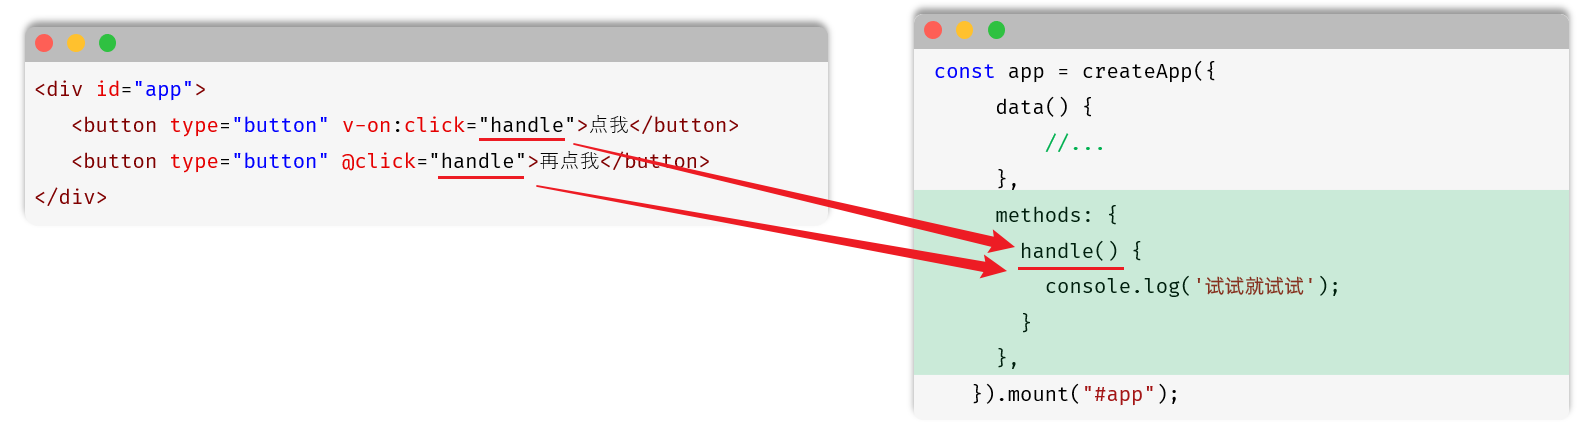

- 为员工列表案例的搜索栏中的查询 和 清空按钮绑定事件：

````html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Tlias智能学习辅助系统</title>
    <style>
      body {
        margin: 0;
      }

      /* 顶栏样式 */
      .header {
        display: flex;
        justify-content: space-between;
        align-items: center;
        background-color: #c2c0c0;
        padding: 20px 20px;
        box-shadow: 0 2px 5px rgba(0,0,0,0.1);
      }
      
      /* 加大加粗标题 */
      .header h1 {
        margin: 0;
        font-size: 24px;
        font-weight: bold;
      }

      /* 文本链接样式 */
      .header a {
        text-decoration: none;
        color: #333;
        font-size: 16px;
      }

      /* 搜索表单区域 */
      .search-form {
        display: flex;
        align-items: center;
        padding: 20px;
        background-color: #f9f9f9;
      }

      /* 表单控件样式 */
      .search-form input[type="text"], .search-form select {
        margin-right: 10px;
        padding: 10px 10px;
        border: 1px solid #ccc;
        border-radius: 4px;
        width: 26%;
      }

      /* 按钮样式 */
      .search-form button {
        padding: 10px 15px;
        margin-left: 10px;
        background-color: #007bff;
        color: white;
        border: none;
        border-radius: 4px;
        cursor: pointer;
      }

      /* 清空按钮样式 */
      .search-form button.clear {
        background-color: #6c757d;
      }

      .table {
         min-width: 100%; 
         border-collapse: collapse;
      }

      /* 设置表格单元格边框 */
      .table td, .table th { 
        border: 1px solid #ddd; 
        padding: 8px; 
        text-align: center;
      }
      
      .avatar { 
        width: 30px; 
        height: 30px; 
        object-fit: cover; 
        border-radius: 50%; 
      }

      /* 页脚版权区域 */
    .footer {
        background-color: #c2c0c0;
        color: white;
        text-align: center;
        padding: 10px 0;
        margin-top: 30px;
    }

    .footer .company-name {
        font-size: 1.1em;
        font-weight: bold;
    }

    .footer .copyright {
        font-size: 0.9em;
    }

    #container {
      width: 80%;
      margin: 0 auto;
    }
    </style>
</head>
<body>
    
  <div id="container">
    <!-- 顶栏 -->
    <div class="header">
      <h1>Tlias智能学习辅助系统</h1>
      <a href="#">退出登录</a>
    </div>
    
    <!-- 搜索表单区域 -->
    <form class="search-form">
      <input type="text" name="name" placeholder="姓名" v-model="searchEmp.name" />
      <select name="gender" v-model="searchEmp.gender">
          <option value="">性别</option>
          <option value="1">男</option>
          <option value="2">女</option>
      </select>
      <select name="job" v-model="searchEmp.job">
          <option value="">职位</option>
          <option value="1">班主任</option>
          <option value="2">讲师</option>
          <option value="3">学工主管</option>
          <option value="4">教研主管</option>
          <option value="5">咨询师</option>
      </select>
      <button type="button" @click="search">查询</button>
      <button type="button" @click="clear">清空</button>
    </form>

    <table class="table table-striped table-bordered">
      <thead>
          <tr>
              <th>姓名</th>
              <th>性别</th>
              <th>头像</th>
              <th>职位</th>
              <th>入职日期</th>
              <th>最后操作时间</th>
              <th>操作</th>
          </tr>
      </thead>
      <tbody>
        <tr v-for="(emp, index) in empList" :key="index">
          <td>{{ emp.name }}</td>
          <td>{{ emp.gender === 1 ? '男' : '女' }}</td>
          <td><img :src="emp.image" alt="{{ emp.name }}" class="avatar"></td>
          <td>
            <span v-if="emp.job === '1'">班主任</span>
            <span v-else-if="emp.job === '2'">讲师</span>
            <span v-else-if="emp.job === '3'">学工主管</span>
            <span v-else-if="emp.job === '4'">教研主管</span>
            <span v-else-if="emp.job === '5'">咨询师</span>
          </td>
          <td>{{ emp.entrydate }}</td>
          <td>{{ emp.updatetime }}</td>
          <td class="btn-group">
            <button class="edit">编辑</button>
            <button class="delete">删除</button>
          </td>
        </tr>
      </tbody>
    </table>

    <!-- 页脚版权区域 -->
    <footer class="footer">
      <p class="company-name">江苏传智播客教育科技股份有限公司</p>
      <p class="copyright">版权所有 Copyright 2006-2024 All Rights Reserved</p>
    </footer>

    <script type="module">
      import { createApp } from 'https://unpkg.com/vue@3/dist/vue.esm-browser.js'
      createApp({
        data() {
          return {
            searchEmp: {
              name: '',
              gender: '',
              job: ''
            },
            empList: [
              { "id": 1,
                "name": "谢逊",
                "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/4.jpg",
                "gender": 1,
                "job": "1",
                "entrydate": "2023-06-09",
                "updatetime": "2024-07-30T14:59:38"
              },
              {
                "id": 2,
                "name": "韦一笑",
                "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg",
                "gender": 1,
                "job": "1",
                "entrydate": "2020-05-09",
                "updatetime": "2023-07-01T00:00:00"
              },
              {
                "id": 3,
                "name": "黛绮丝",
                "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/2.jpg",
                "gender": 2,
                "job": "2",
                "entrydate": "2021-06-01",
                "updatetime": "2023-07-01T00:00:00"
              }
            ]
          }
        },
        methods: {
          search() {
            console.log(this.searchEmp)
          },
          clear() {
            this.searchEmp = {
              name: '',
              gender: '',
              job: ''
            }
          }
        }
      }).mount('#container')
    </script>

  </div>

</body>
</html>
````

> **勘误：**Vue 不在普通 HTML 属性值里解析双大括号，`alt="{{ emp.name }}"` 应改为 `:alt="emp.name"`。原案例多处使用 `:key="index"`；本例已有唯一 `id`，跟练时改为 `:key="emp.id"`，让列表身份与员工对应。

<strong>注意： methods函数中的this指向Vue实例，可以通过this获取到data中定义的数据。</strong>

> **补充：**本章的 `methods` 应写普通方法，如 `search() { ... }`，不要写成 `search: () => { ... }`。箭头函数不会建立 Vue 方法需要的 `this`。但方法内部的 `.then(res => { this.empList = ... })` 正好能沿用外层 `this`。当前 `search()` 只打印条件，实际请求在 Ajax 小节实现。


## 6 Ajax


### 6.1 概述

我们前端页面中的数据，如下图所示的表格中的员工信息，应该来自于后台，那么我们的后台和前端是互不影响的2个程序，那么我们前端应该如何从后台获取数据呢？因为是2个程序，所以必须涉及到2个程序的交互，所以这就需要用到我们接下来学习的Ajax技术。

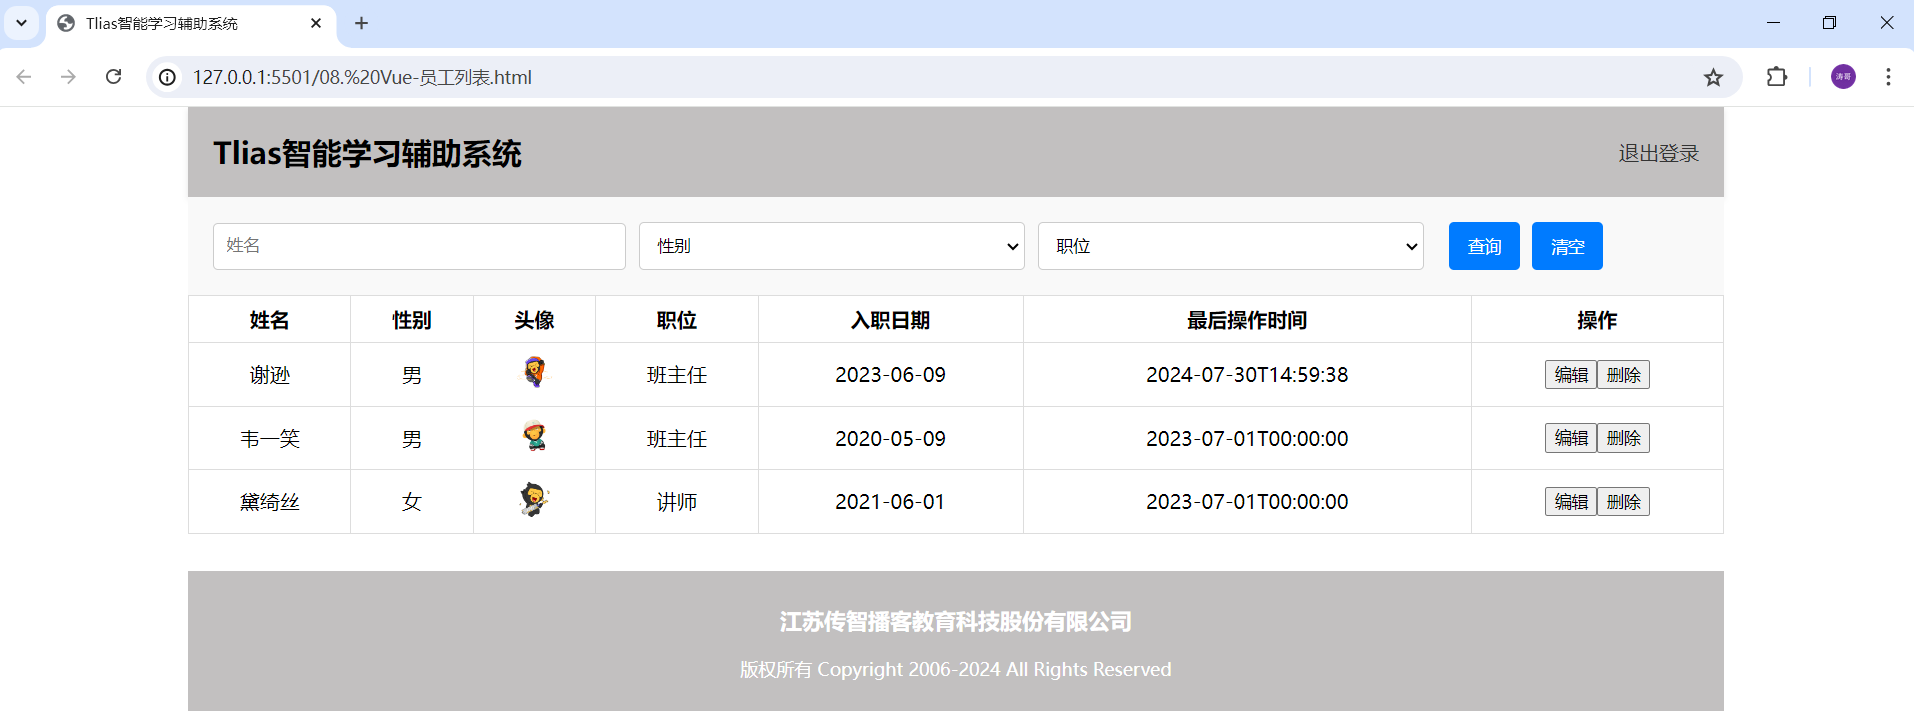

<strong>Ajax:</strong> 全称Asynchronous JavaScript And XML，异步的JavaScript和XML。其作用有如下2点：

- 与服务器进行数据交换：通过Ajax可以给服务器发送请求，并获取服务器响应的数据。
- 异步交互：可以在<strong>不重新加载整个页面</strong>的情况下，与服务器交换数据并<strong>更新部分网页</strong>的技术，如：搜索联想、用户名是否可用的校验等等。

我们详细的解释一下Ajax技术的2个作用：

- 与服务器进行数据交互

如下图所示前端资源被浏览器解析，但是前端页面上缺少数据，前端可以通过Ajax技术，向后台服务器发起请求，后台服务器接受到前端的请求，从数据库中获取前端需要的资源，然后响应给前端，前端在通过我们学习的vue技术，可以将数据展示到页面上，这样用户就能看到完整的页面了。此处可以对比JavaSE中的网络编程技术来理解。

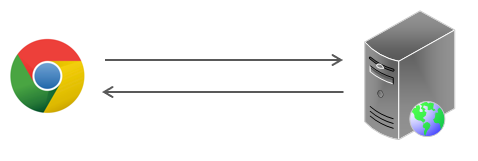

- 异步交互：可以在<strong>不重新加载整个页面</strong>的情况下，与服务器交换数据并<strong>更新部分网页</strong>的技术。

如下图所示，当我们再百度搜索java时，下面的联想数据是通过Ajax请求从后台服务器得到的，在整个过程中，我们的Ajax请求不会导致整个百度页面的重新加载，并且只针对搜索栏这局部模块的数据进行了数据的更新，不会对整个页面的其他地方进行数据的更新，这样就大大提升了页面的加载速度，用户体验高。

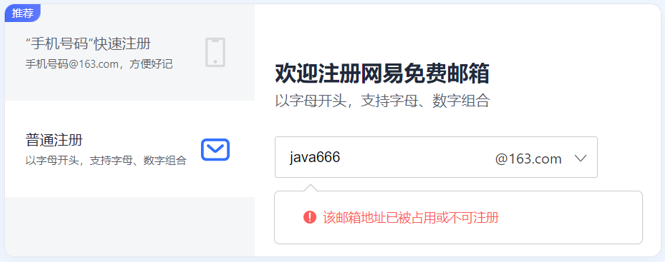

> XML：（英语：E<strong>x</strong>tensible <strong>M</strong>arkup <strong>L</strong>anguage）可扩展标记语言，本质是一种数据格式，可以用来存储复杂的数据结构。
> 
> > **补充：**Ajax 名称保留了 XML，但现代接口经常返回 JSON。本章 Axios 返回 JSON 数据后交给 Vue 渲染，不要求使用 XML。


### 6.2 同步异步

针对于上述Ajax的局部刷新功能是因为Ajax请求是异步的，与之对应的有同步请求。接下来我们介绍一下异步请求和同步请求的区别。

> **补充：**“不整页跳转”与“异步等待”要分开理解：脚本拿到响应后主动修改数据或 DOM，才形成局部更新；异步使等待网络结果时页面仍可处理其他任务。这里的同步示意针对阻塞主线程的等待，不应理解为所有普通 HTTP 访问都会冻结浏览器。

- <strong>同步请求</strong>发送过程如下图所示：

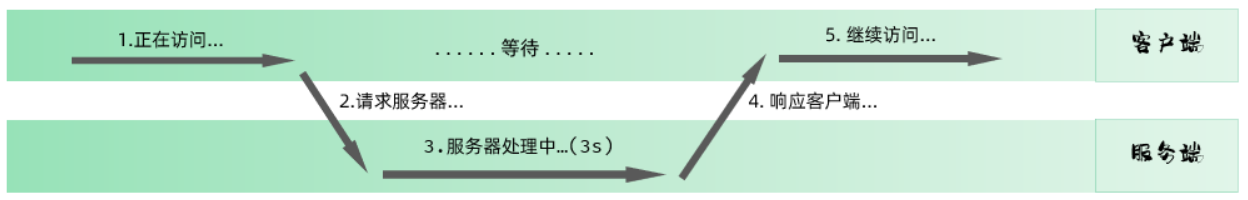

浏览器页面在发送请求给服务器，在服务器处理请求的过程中，浏览器页面不能做其他的操作。只能等到服务器响应结束后才能，浏览器页面才能继续做其他的操 作。 

- <strong>异步请求</strong>发送过程如下图所示：

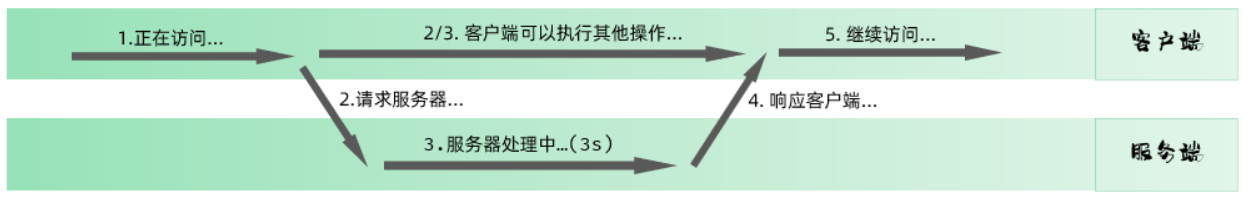

 浏览器页面发送请求给服务器，在服务器处理请求的过程中，浏览器页面还可以做其他的操作。


### 6.3 Axios

使用原生的Ajax请求的代码编写起来还是比较繁琐的，所以接下来我们学习一门更加简单的发送Ajax请求的技术Axios 。Axios是对原生的AJAX进行封装，简化书写。Axios官网是：<code>https://www.axios-http.cn</code>

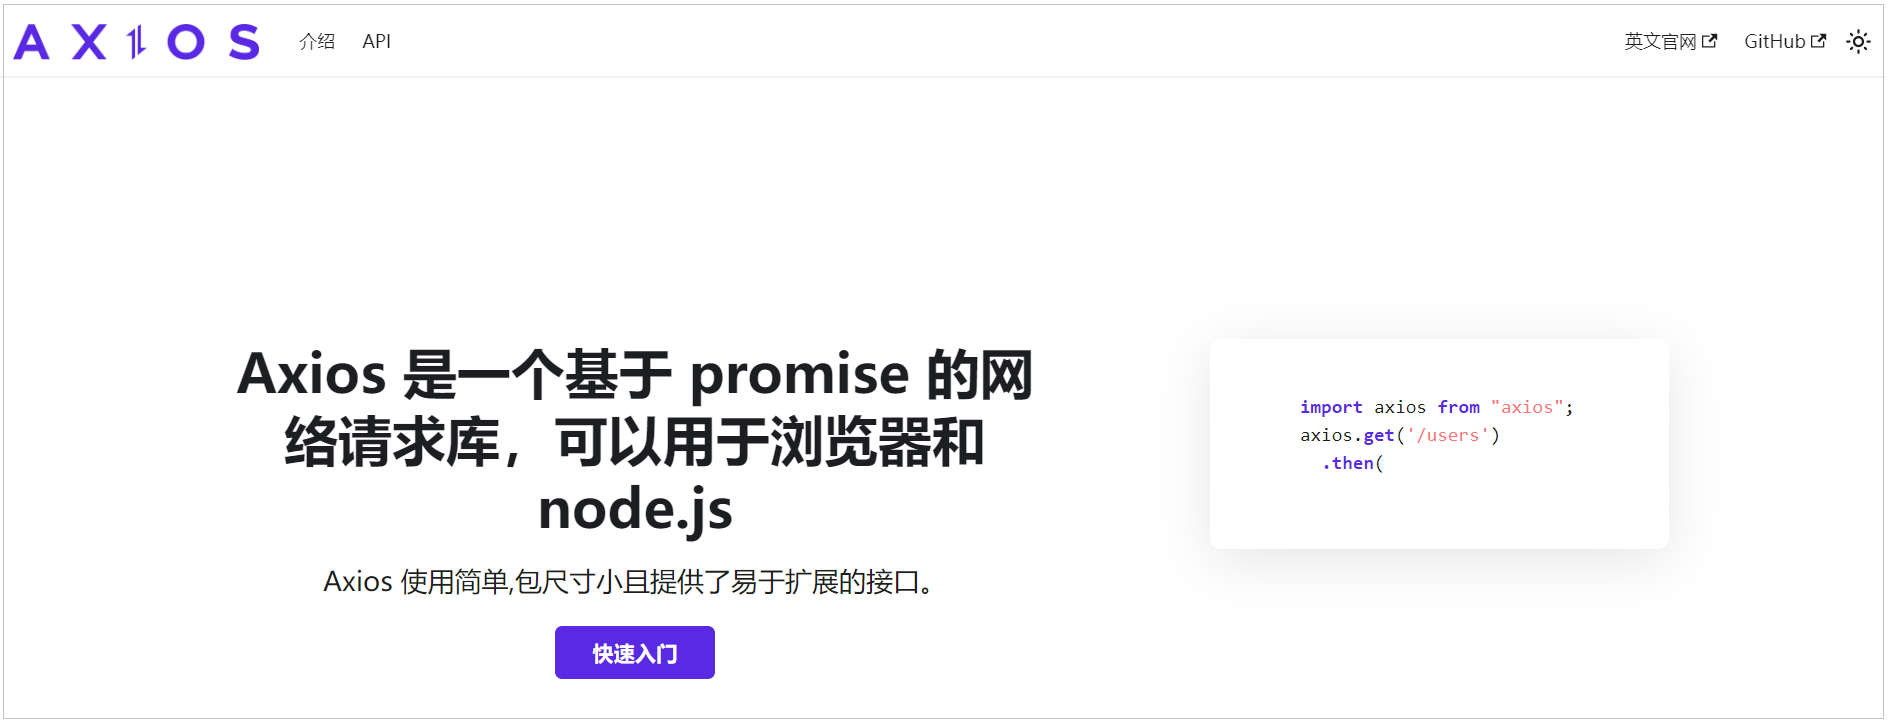


#### 6.3.1 入门程序

Axios的使用比较简单，主要分为2步：

1). 引入Axios文件（如果网络不通畅，可以使用离线的已经下载好的js文件，资料中已经提供）

````html
<script src="https://unpkg.com/axios/dist/axios.min.js"></script>
````

2). 点击按钮时，使用Axios发送请求

````html
<!DOCTYPE html>
<html lang="en">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <title>Axios入门程序</title>
</head>
<body>

  <button id="getData">GET</button>
  <button id="postData">POST</button>
  
  <script src="https://unpkg.com/axios/dist/axios.min.js"></script>
  <script>
    //GET请求
    document.querySelector('#getData').onclick = function() {
      axios({
        url:'https://mock.apifox.cn/m1/3083103-0-default/emps/list',
        method:'get'
      }).then(function(res) {
        console.log(res.data);
      }).catch(function(err) {
        console.log(err);
      })
    }
    
    //POST请求
    document.querySelector('#postData').onclick = function() {
      axios({
        url:'https://mock.apifox.cn/m1/3083103-0-default/emps/update',
        method:'post'
      }).then(function(res) {
        console.log(res.data);
      }).catch(function(err) {
        console.log(err);
      })
    }
  </script>
</body>
</html>
````

> 知识小贴士：在使用axios时，在axios之后，输入 thenc 会自动生成成功及失败回调函数结构 。
> 
> > **补充：**`thenc` 属于编辑器或扩展提供的代码片段提示，不是 JavaScript 或 Axios 的关键字。没有该提示时，手工写 `.then(...).catch(...)` 即可。


#### 6.3.2 请求方法别名

Axios还针对不同的请求，提供了别名方式的api，具体格式如下：

axios.请求方式(url &#91;, data &#91;, config&#93;&#93;)

具体如下：

| 方法 | 描述 |
| --- | --- |
| axios.get(url &#91;, config&#93;) | 发送get请求 |
| axios.delete(url &#91;, config&#93;) | 发送delete请求 |
| axios.post(url &#91;, data&#91;, config&#93;&#93;) | 发送post请求 |
| axios.put(url &#91;, data&#91;, config&#93;&#93;) | 发送put请求 |

> **补充：**GET 的第二个参数是配置对象：`axios.get(url, { params: { name: '谢逊' } })`；POST 的第二个参数是请求体数据，第三个才是配置：`axios.post(url, { id: 1 }, config)`。不能把 POST 的参数顺序直接套给 GET。用 `params` 可以自动编码中文、空格和 `&` 等字符，比手工拼查询串更稳妥。

我们目前只关注get和post请求，所以在上述的入门案例中，我们可以将get请求代码改写成如下：

````javascript
axios.get("https://mock.apifox.cn/m1/3083103-0-default/emps/list").then(result => {
    console.log(result.data);
})
````

post请求改写成如下：

````javascript
axios.post("https://mock.apifox.cn/m1/3083103-0-default/emps/update","id=1").then(result => {
    console.log(result.data);
})
````

> **补充：**`"id=1"` 是字符串形式的请求体，不等同于 `{ id: 1 }` 这个对象。发送 JSON 对象还是表单编码，应以接口约定为准；服务端处理的名称、类型与 `Content-Type` 要对应。练习中的公共 POST 地址只用于课程演示，不要拿真实业务接口做随意修改测试。


### 6.4 案例-异步获取数据

> **接口可用性说明（2026-09-27）：**本次读取 `https://web-server.itheima.net/emps/list` 得到 HTTP 405，响应正文显示请求被站点安全策略拦截。这只能说明本次环境未能取得业务数据，不能据此推断接口已永久关闭或应改用 POST。下文保留讲义地址；第 7 节提供同字段的本地 JSON 练习方案。

需求：基于axios动态加载员工列表数据

具体代码实现如下：

````html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Tlias智能学习辅助系统</title>
    <style>
      body {
        margin: 0;
      }

      /* 顶栏样式 */
      .header {
        display: flex;
        justify-content: space-between;
        align-items: center;
        background-color: #c2c0c0;
        padding: 20px 20px;
        box-shadow: 0 2px 5px rgba(0,0,0,0.1);
      }
      
      /* 加大加粗标题 */
      .header h1 {
        margin: 0;
        font-size: 24px;
        font-weight: bold;
      }

      /* 文本链接样式 */
      .header a {
        text-decoration: none;
        color: #333;
        font-size: 16px;
      }

      /* 搜索表单区域 */
      .search-form {
        display: flex;
        align-items: center;
        padding: 20px;
        background-color: #f9f9f9;
      }

      /* 表单控件样式 */
      .search-form input[type="text"], .search-form select {
        margin-right: 10px;
        padding: 10px 10px;
        border: 1px solid #ccc;
        border-radius: 4px;
        width: 26%;
      }

      /* 按钮样式 */
      .search-form button {
        padding: 10px 15px;
        margin-left: 10px;
        background-color: #007bff;
        color: white;
        border: none;
        border-radius: 4px;
        cursor: pointer;
      }

      /* 清空按钮样式 */
      .search-form button.clear {
        background-color: #6c757d;
      }

      .table {
         min-width: 100%; 
         border-collapse: collapse;
      }

      /* 设置表格单元格边框 */
      .table td, .table th { 
        border: 1px solid #ddd; 
        padding: 8px; 
        text-align: center;
      }
      
      .avatar { 
        width: 30px; 
        height: 30px; 
        object-fit: cover; 
        border-radius: 50%; 
      }

      /* 页脚版权区域 */
    .footer {
        background-color: #c2c0c0;
        color: white;
        text-align: center;
        padding: 10px 0;
        margin-top: 30px;
    }

    .footer .company-name {
        font-size: 1.1em;
        font-weight: bold;
    }

    .footer .copyright {
        font-size: 0.9em;
    }

    #container {
      width: 80%;
      margin: 0 auto;
    }
    </style>
</head>
<body>
    
  <div id="container">
    <!-- 顶栏 -->
    <div class="header">
      <h1>Tlias智能学习辅助系统</h1>
      <a href="#">退出登录</a>
    </div>
    
    <!-- 搜索表单区域 -->
    <form class="search-form">
      <input type="text" name="name" placeholder="姓名" v-model="searchForm.name" />
      <select name="gender" v-model="searchForm.gender">
          <option value="">性别</option>
          <option value="1">男</option>
          <option value="2">女</option>
      </select>
      <select name="job" v-model="searchForm.job">
          <option value="">职位</option>
          <option value="1">班主任</option>
          <option value="2">讲师</option>
          <option value="3">学工主管</option>
          <option value="4">教研主管</option>
          <option value="5">咨询师</option>
      </select>
      <button type="button" @click="search">查询</button>
      <button type="button" @click="clear">清空</button>
    </form>

    <table class="table table-striped table-bordered">
      <thead>
          <tr>
              <th>姓名</th>
              <th>性别</th>
              <th>头像</th>
              <th>职位</th>
              <th>入职日期</th>
              <th>最后操作时间</th>
              <th>操作</th>
          </tr>
      </thead>
      <tbody>
        <tr v-for="(emp, index) in empList" :key="index">
          <td>{{ emp.name }}</td>
          <td>{{ emp.gender === 1 ? '男' : '女' }}</td>
          <td><img :src="emp.image" alt="{{ emp.name }}" class="avatar"></td>
          
           <!-- 基于v-if/v-else-if/v-else指令来展示职位这一列 -->
          <td>
            <span v-if="emp.job == '1'">班主任</span>
            <span v-else-if="emp.job == '2'">讲师</span>
            <span v-else-if="emp.job == '3'">学工主管</span>
            <span v-else-if="emp.job == '4'">教研主管</span>
            <span v-else-if="emp.job == '5'">咨询师</span>
            <span v-else>其他</span>
          </td>

          <!-- 基于v-show指令来展示职位这一列 -->
          <!-- <td>
            <span v-show="emp.job === '1'">班主任</span>
            <span v-show="emp.job === '2'">讲师</span>
            <span v-show="emp.job === '3'">学工主管</span>
            <span v-show="emp.job === '4'">教研主管</span>
            <span v-show="emp.job === '5'">咨询师</span>
         </td> -->

          <td>{{ emp.entrydate }}</td>
          <td>{{ emp.updatetime }}</td>
          <td class="btn-group">
            <button class="edit">编辑</button>
            <button class="delete">删除</button>
          </td>
        </tr>
      </tbody>
    </table>

    <!-- 页脚版权区域 -->
    <footer class="footer">
      <p class="company-name">江苏传智播客教育科技股份有限公司</p>
      <p class="copyright">版权所有 Copyright 2006-2024 All Rights Reserved</p>
    </footer>

    <script src="https://unpkg.com/axios/dist/axios.min.js"></script>
    <script type="module">
      import { createApp } from 'https://unpkg.com/vue@3/dist/vue.esm-browser.js'
      createApp({
        data() {
          return {
            searchForm: {
              name: '',
              gender: '',
              job: ''
            },
            empList: []
          }
        },
        methods: {
          search() {
            //基于axios发送异步请求，请求https://web-server.itheima.net/emps/list，根据条件查询员工列表
            axios.get(`https://web-server.itheima.net/emps/list?name=${this.searchForm.name}&gender=${this.searchForm.gender}&job=${this.searchForm.job}`).then(res => {
              this.empList = res.data.data
            })
          },
          clear() {
            this.searchForm= {
              name: '',
              gender: '',
              job: ''
            }
          }
        }
      }).mount('#container')
    </script>

  </div>

</body>
</html>
````

> **勘误：**Vue 不在普通 HTML 属性值里解析双大括号，`alt="{{ emp.name }}"` 应改为 `:alt="emp.name"`。原案例多处使用 `:key="index"`；本例已有唯一 `id`，跟练时改为 `:key="emp.id"`，让列表身份与员工对应。

如果使用axios中提供的.then(function(){....}).catch(function(){....})，这种回调函数的写法，会使得代码的可读性和维护性变差。 而为了解决这个问题，我们可以使用两个关键字，分别是：<strong>async、await</strong>。 

可以通过async、await可以让异步变为同步操作。async就是来声明一个异步方法，await是用来等待异步任务执行。

> **勘误：**`async/await` 不会把网络请求变成阻塞浏览器的同步请求。`await` 暂停的是当前异步函数后续部分，主线程仍能处理其他任务；它只是让有先后依赖的异步步骤更像顺序代码。`.then` 与 `await` 都是处理 Promise 的方式，并不存在前者必然可读性差的结论。

<strong>代码修改前：</strong>

````javascript
search() {
    //基于axios发送异步请求，请求https://web-server.itheima.net/emps/list，根据条件查询员工列表
    axios.get(`https://web-server.itheima.net/emps/list?name=${this.searchForm.name}&gender=${this.searchForm.gender}&job=${this.searchForm.job}`).then(res => {
      this.empList = res.data.data
    })
  },
````

<strong>代码修改后：</strong>

````javascript
  async search() {
    //基于axios发送异步请求，请求https://web-server.itheima.net/emps/list，根据条件查询员工列表
    const result = await axios.get(`https://web-server.itheima.net/emps/list?name=${this.searchForm.name}&gender=${this.searchForm.gender}&job=${this.searchForm.job}`);
    this.empList = result.data.data;
  },
````

> **代码位置说明：**这一段是 Vue 选项对象中的方法片段，要放在 `methods: { ... }` 内，并保留同级 `data()` 与挂载代码；它不是可以直接粘贴为独立 JS 文件的完整程序。调用 `async` 方法会得到 Promise，`await` 后面的赋值要等请求成功后才执行，失败应由 `try/catch` 或调用方捕获。

修改后，代码就变成同步操作了，一行一行的从前往后执行。 在前端项目开发中，经常使用这两个关键字配合，使得代码的可读性和可维护性变高。

> **勘误：**`async/await` 不会把网络请求变成阻塞浏览器的同步请求。`await` 暂停的是当前异步函数后续部分，主线程仍能处理其他任务；它只是让有先后依赖的异步步骤更像顺序代码。`.then` 与 `await` 都是处理 Promise 的方式，并不存在前者必然可读性差的结论。


## 7 Vue生命周期


### 7.1 介绍

vue的生命周期：指的是vue对象从创建到销毁的过程。

vue的生命周期包含8个阶段：每触发一个生命周期事件，会自动执行一个生命周期方法，这些生命周期方法也被称为钩子方法。其完整的生命周期如下图所示：

| 状态 | 阶段周期 |
| --- | --- |
| beforeCreate | 创建前 |
| created | 创建后 |
| beforeMount | 挂载前 |
| mounted | 挂载完成 |
| beforeUpdate | 更新前 |
| updated | 更新后 |
| beforeDestroy | 销毁前 |
| destroyed | 销毁后 |

> **勘误：**原表最后两项 `beforeDestroy / destroyed` 是 Vue 2 名称。本章使用 Vue 3，应对应 `beforeUnmount / unmounted`。下方讲义生命周期图展示的已经是 Vue 3 名称。

| Vue 3 选项式钩子 | 什么时候执行 | 本章应如何理解 |
| --- | --- | --- |
| `beforeCreate` | 组件状态初始化前 | 此时不要依赖尚未初始化的 `data`、`methods` |
| `created` | 组件状态初始化后 | 可访问数据和方法，DOM 尚未挂载 |
| `beforeMount` | 初次挂载前 | 即将把初次渲染结果放入页面 |
| `mounted` | 初次挂载完成 | 本章在这里发起员工列表查询 |
| `beforeUpdate` | 响应式状态引起 DOM 更新前 | 数据已经变化，DOM 尚未完成本次更新 |
| `updated` | DOM 更新完成后 | 不要在此无条件改数据并反复触发更新 |
| `beforeUnmount` | 卸载前 | 可以开始清理副作用 |
| `unmounted` | 卸载完成后 | 确认定时器、手工监听等已清理 |

> **补充：**这八项是本章介绍的主要钩子，并非 Vue 所有生命周期 API 的完整清单。`mounted` 不表示图片、异步组件和网络数据都已经加载完毕；其中的异步请求完成后，还会引起一次界面更新。

下图是 Vue 官网提供的从创建 Vue 到效果 Vue 对象的整个过程及各个阶段对应的钩子函数：

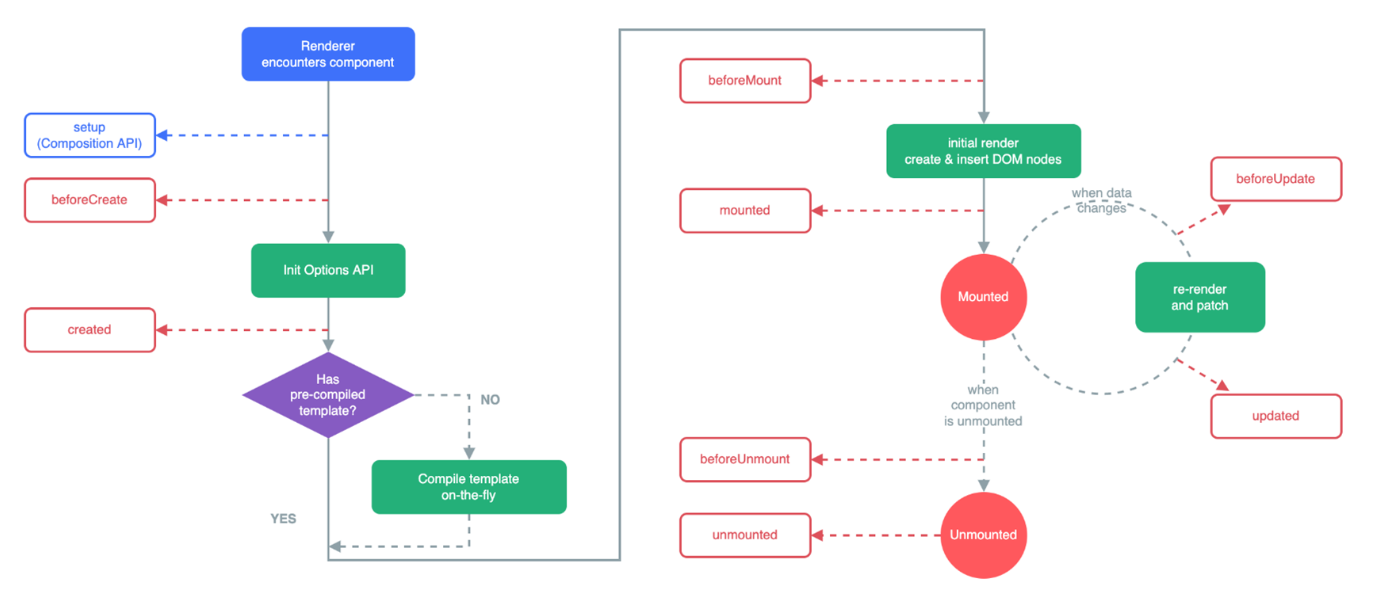

其中我们需要重点关注的是mounted，其他的我们了解即可。

mounted：挂载完成，Vue初始化成功，HTML页面渲染成功。<strong>以后我们一般用于页面初始化自动的ajax请求后台数据</strong>


### 7.2 案例完善

那我们要想在页面加载完毕，就查询出员工列表，就可以在mounted钩子函数中，发送异步请求查询员工数据了。 

具体代码如下：

````javascript
    methods: {
      async search() {
        //基于axios发送异步请求，请求https://web-server.itheima.net/emps/list，根据条件查询员工列表
        const result = await axios.get(`https://web-server.itheima.net/emps/list?name=${this.searchForm.name}&gender=${this.searchForm.gender}&job=${this.searchForm.job}`);
        this.empList = result.data.data;
      },
      clear() {
        this.searchForm= {
          name: '',
          gender: '',
          job: ''
        }
        this.search();
      }
    },
    mounted() {
      this.search();
    }
  }).mount('#container')
````

> **代码位置说明：**这一段是 Vue 选项对象中的方法片段，要放在 `methods: { ... }` 内，并保留同级 `data()` 与挂载代码；它不是可以直接粘贴为独立 JS 文件的完整程序。调用 `async` 方法会得到 Promise，`await` 后面的赋值要等请求成功后才执行，失败应由 `try/catch` 或调用方捕获。

到此，员工列表查询的功能我们就已经完成了。 那关于Vue的其他高级用法，我们将在后面的前端web实战中来详细讲解。


### 7.3 补充：把前面的片段合成最终页面

讲义先给出了完整的查询页面，后来用局部代码替换成 `async/await`，最后补入 `mounted` 和清空后重新查询。下面合并这些步骤，并修正动态 `alt`、列表 `key`、参数编码和数字/字符串比较问题。查询失败时会显示原因，不会把错误当成空数组默默略过。

这一版保留本章范围：员工列表显示、条件查询、清空并重新查询、页面挂载自动查询。编辑、删除、退出登录仍是界面占位，不包含后端业务实现。原生 DOM 示例中的删除只是移除当前页面的一行；在 Vue 列表里应通过修改数组更新界面，不应直接移除 Vue 管理的 `tr`。

把下面内容保存为 `employees.html`，通过 Live Server 打开。固定依赖版本为本次验证所用的 Vue `3.5.43` 与 Axios `1.20.0`。`v-cloak` 防止加载期间露出模板表达式；若依赖脚本加载失败，页面可能一直被隐藏，此时先查看控制台和网络面板。

````html
<!DOCTYPE html>
<html lang="zh-CN">
<head>
    <meta charset="UTF-8">
    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <title>Tlias智能学习辅助系统</title>
    <style>
      body {
        margin: 0;
      }

      /* 顶栏样式 */
      .header {
        display: flex;
        justify-content: space-between;
        align-items: center;
        background-color: #c2c0c0;
        padding: 20px 20px;
        box-shadow: 0 2px 5px rgba(0,0,0,0.1);
      }
      
      /* 加大加粗标题 */
      .header h1 {
        margin: 0;
        font-size: 24px;
        font-weight: bold;
      }

      /* 文本链接样式 */
      .header a {
        text-decoration: none;
        color: #333;
        font-size: 16px;
      }

      /* 搜索表单区域 */
      .search-form {
        display: flex;
        align-items: center;
        padding: 20px;
        background-color: #f9f9f9;
      }

      /* 表单控件样式 */
      .search-form input[type="text"], .search-form select {
        margin-right: 10px;
        padding: 10px 10px;
        border: 1px solid #ccc;
        border-radius: 4px;
        width: 26%;
      }

      /* 按钮样式 */
      .search-form button {
        padding: 10px 15px;
        margin-left: 10px;
        background-color: #007bff;
        color: white;
        border: none;
        border-radius: 4px;
        cursor: pointer;
      }

      /* 清空按钮样式 */
      .search-form button.clear {
        background-color: #6c757d;
      }

      .table {
         min-width: 100%; 
         border-collapse: collapse;
      }

      /* 设置表格单元格边框 */
      .table td, .table th { 
        border: 1px solid #ddd; 
        padding: 8px; 
        text-align: center;
      }
      
      .avatar { 
        width: 30px; 
        height: 30px; 
        object-fit: cover; 
        border-radius: 50%; 
      }

      /* 页脚版权区域 */
    .footer {
        background-color: #c2c0c0;
        color: white;
        text-align: center;
        padding: 10px 0;
        margin-top: 30px;
    }

    .footer .company-name {
        font-size: 1.1em;
        font-weight: bold;
    }

    .footer .copyright {
        font-size: 0.9em;
    }

    #container {
      width: 80%;
      margin: 0 auto;
    }
    [v-cloak] { display: none; }
    .request-error { color: #b42318; padding: 0 20px; }
    .search-form { flex-wrap: wrap; gap: 10px; }
    .search-form button:disabled { opacity: 0.6; cursor: wait; }
    </style>
</head>
<body>
    
  <div id="container" v-cloak>
    <!-- 顶栏 -->
    <div class="header">
      <h1>Tlias智能学习辅助系统</h1>
      <a href="#">退出登录</a>
    </div>
    
    <!-- 搜索表单区域 -->
    <form class="search-form" @submit.prevent="search">
      <input type="text" name="name" placeholder="姓名" v-model="searchForm.name" />
      <select name="gender" v-model="searchForm.gender">
          <option value="">性别</option>
          <option value="1">男</option>
          <option value="2">女</option>
      </select>
      <select name="job" v-model="searchForm.job">
          <option value="">职位</option>
          <option value="1">班主任</option>
          <option value="2">讲师</option>
          <option value="3">学工主管</option>
          <option value="4">教研主管</option>
          <option value="5">咨询师</option>
      </select>
      <button type="submit" :disabled="loading">{{ loading ? '查询中…' : '查询' }}</button>
      <button type="button" @click="clear" :disabled="loading">清空</button>
    </form>
    <p v-if="error" class="request-error" role="alert">{{ error }}</p>
    <p v-if="loading">正在加载员工数据……</p>
    <p v-if="!loading && !error && empList.length === 0">没有符合条件的员工。</p>

    <table class="table table-striped table-bordered">
      <thead>
          <tr>
              <th>姓名</th>
              <th>性别</th>
              <th>头像</th>
              <th>职位</th>
              <th>入职日期</th>
              <th>最后操作时间</th>
              <th>操作</th>
          </tr>
      </thead>
      <tbody>
        <tr v-for="(emp, index) in empList" :key="emp.id">
          <td>{{ emp.name }}</td>
          <td>{{ emp.gender === 1 ? '男' : (emp.gender === 2 ? '女' : '未知') }}</td>
          <td><img :src="emp.image" :alt="emp.name" class="avatar"></td>
          
           <!-- 基于v-if/v-else-if/v-else指令来展示职位这一列 -->
          <td>
            <span v-if="emp.job === 1">班主任</span>
            <span v-else-if="emp.job === 2">讲师</span>
            <span v-else-if="emp.job === 3">学工主管</span>
            <span v-else-if="emp.job === 4">教研主管</span>
            <span v-else-if="emp.job === 5">咨询师</span>
            <span v-else>其他</span>
          </td>

          <td>{{ emp.entrydate }}</td>
          <td>{{ emp.updatetime }}</td>
          <td class="btn-group">
            <button class="edit">编辑</button>
            <button class="delete">删除</button>
          </td>
        </tr>
      </tbody>
    </table>

    <!-- 页脚版权区域 -->
    <footer class="footer">
      <p class="company-name">江苏传智播客教育科技股份有限公司</p>
      <p class="copyright">版权所有 Copyright 2006-2024 All Rights Reserved</p>
    </footer>

  </div>

  <script src="https://unpkg.com/axios@1.20.0/dist/axios.min.js"></script>
  <script type="module">
    import { createApp } from 'https://unpkg.com/vue@3.5.43/dist/vue.esm-browser.js';

    // 公共接口不可达时改为 true，并把本节提供的 emps.json 放在 HTML 同目录。
    const LOCAL_DEMO = false;
    const API_URL = LOCAL_DEMO
      ? './emps.json'
      : 'https://web-server.itheima.net/emps/list';

    createApp({
      data() {
        return {
          searchForm: { name: '', gender: '', job: '' },
          empList: [],
          loading: false,
          error: ''
        };
      },
      methods: {
        async search() {
          if (this.loading) return;
          const filters = { ...this.searchForm };
          this.loading = true;
          this.error = '';
          this.empList = [];
          try {
            const result = await axios.get(API_URL, {
              params: LOCAL_DEMO ? undefined : filters,
              timeout: 10000
            });
            const body = result.data;
            if (!body || !Array.isArray(body.data)) {
              throw new Error('响应格式不符：预期 result.data.data 是员工数组');
            }
            let employees = body.data.map(emp => ({
              ...emp,
              gender: Number(emp.gender),
              job: Number(emp.job)
            }));
            // 静态 JSON 不处理查询条件，本地演示时由浏览器筛选。
            if (LOCAL_DEMO) {
              employees = employees.filter(emp =>
                (!filters.name || String(emp.name).includes(filters.name)) &&
                (!filters.gender || emp.gender === Number(filters.gender)) &&
                (!filters.job || emp.job === Number(filters.job))
              );
            }
            this.empList = employees;
          } catch (error) {
            this.error = error.response
              ? '查询失败：HTTP ' + error.response.status + '，请检查接口或切换本地练习模式。'
              : '查询失败：' + error.message;
          } finally {
            this.loading = false;
          }
        },
        clear() {
          if (this.loading) return;
          this.searchForm = { name: '', gender: '', job: '' };
          this.search();
        }
      },
      mounted() {
        this.search();
      }
    }).mount('#container');
  </script>
</body>
</html>
````


### 7.4 补充：公共接口不可用时，用本地 JSON 跟练

本次环境访问讲义员工接口得到站点拦截页面，而 Vue 与 Axios 文件可以正常获取。因此，下面的本地方案用于练习完整流程，不把模拟数据当作真实接口返回值。

1. 将上一节代码中的 `const LOCAL_DEMO = false;` 改为 `true`。
2. 在 `employees.html` 同一目录创建 `emps.json`，复制下面的数据。
3. 用 Live Server 打开 HTML；首次进入自动读取 JSON，输入姓名、性别或职位后点击查询，点击清空恢复全部数据。

这里仍然通过 Axios 异步读取 JSON 文件，但静态文件不会处理查询参数，因此本地模式由浏览器过滤这三条数据。真实模式则使用 `params` 把条件发给服务端，由服务端查询。

下面三名员工及字段来自讲义静态数组；外层 `code / msg / data` 是本地练习的响应包装，重点是和讲义的 `result.data.data` 访问方式一致。

````json
{
  "code": 1,
  "msg": "success",
  "data": [
    {
      "id": 1,
      "name": "谢逊",
      "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/4.jpg",
      "gender": 1,
      "job": "1",
      "entrydate": "2023-06-09",
      "updatetime": "2024-07-30T14:59:38"
    },
    {
      "id": 2,
      "name": "韦一笑",
      "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/1.jpg",
      "gender": 1,
      "job": "1",
      "entrydate": "2020-05-09",
      "updatetime": "2023-07-01T00:00:00"
    },
    {
      "id": 3,
      "name": "黛绮丝",
      "image": "https://web-framework.oss-cn-hangzhou.aliyuncs.com/2023/2.jpg",
      "gender": 2,
      "job": "2",
      "entrydate": "2021-06-01",
      "updatetime": "2023-07-01T00:00:00"
    }
  ]
}
````

**数据怎样流动：**

1. 用户输入触发 `v-model`，更新 `searchForm`。
2. `search()` 拷贝当前条件，经 `axios.get` 发起请求。
3. `await` 等待响应，`result` 是 Axios 响应对象，`result.data` 是响应体，`result.data.data` 才是员工数组。
4. 对 `gender/job` 做统一数值转换；本地模式再根据当前条件过滤。
5. 给 `this.empList` 重新赋值，Vue 根据 `v-for` 更新页面。
6. `clear()` 清空数据模型并再次调用 `search()`；`mounted()` 在初次挂载后调用同一个方法。

`try/catch/finally` 分别负责执行请求、展示失败信息、结束加载状态。加载期间禁用查询和清空，避免同时发起多个查询导致旧响应覆盖新结果。真实接口返回结构若改变，要先查看“网络 → 响应”，再调整取数组的位置，不能盲目增加或减少一个 `.data`。

**跟练检查：**初次显示 3 人；姓名“谢逊”显示 1 人；性别“女”与职位“讲师”组合显示“黛绮丝”；不存在的名字显示空结果；清空回到 3 人。把 `emps.json` 临时改名会触发错误提示，恢复文件后再次查询应恢复。

若要离线运行，把相同版本的依赖保存到项目中：将 Axios 的 `src` 改为 `js/axios.min.js`，将 Vue 的模块导入改为 `./js/vue.esm-browser.js`。数据文件也要通过本地 HTTP 服务读取，不能把“笔记配图可离线阅读”理解为所有远程依赖都会自动下载。


## 8 附录

- <strong>Ajax练习的url地址：</strong>

    - Ajax演示：

        - GET请求:  https://mock.apifox.cn/m1/3083103-0-default/emps/list
        - POST请求: https://mock.apifox.cn/m1/3083103-0-default/emps/update
    - Ajax员工列表案例地址： 

        - https://web-server.itheima.net/emps/list
        - https://web-server.itheima.net/emps/list?name=xxx&amp;gender=xxx&amp;job=xxx

- <strong>Chrome浏览器插件地址：</strong>https://chrome.zzzmh.cn/&#35;/index

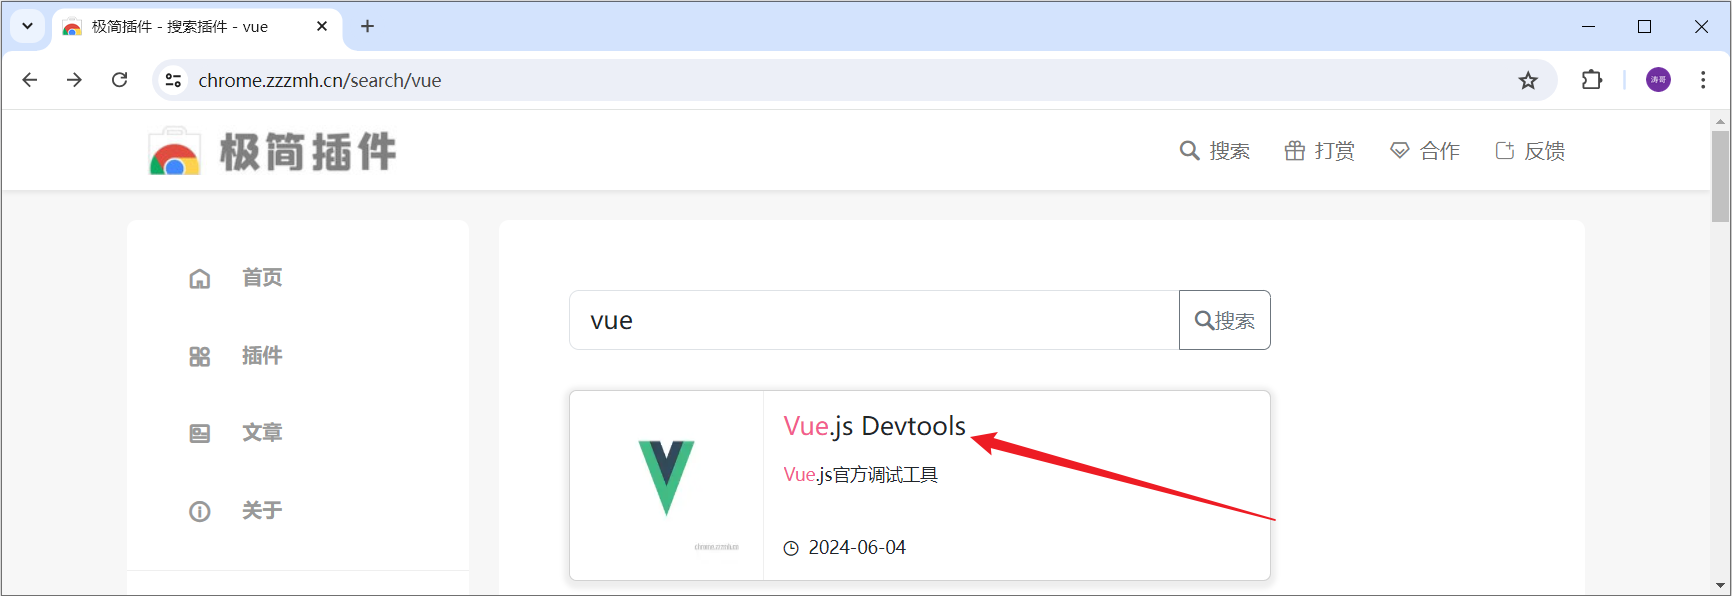


### 8.1 补充：运行时按现象排查

| 现象 | 优先检查 |
| --- | --- |
| 对象例子报 `user.eat is not a function` | 讲义笔误；对象定义的是 `sing`，调用改为 `user.sing()` |
| 第一个标题无法修改 | 元素是否已加载、选择器是否匹配、返回值是否为 `null` 或空列表 |
| 页面显示 `{{message}}` | Vue 模块加载、`type="module"`、挂载区域及控制台错误 |
| 图片替代文字出现 `{{ emp.name }}` | 改成 `:alt="emp.name"`，HTML 属性不使用文本插值语法 |
| 职位为空或性别显示不对 | 核对接口返回的是字符串还是数字，与比较表达式保持一致 |
| 点击查询整页跳转 | 使用 `@submit.prevent` 或明确设置 `type="button"`，阻止不需要的原生提交 |
| 清空后表单数据不一致 | 修改 `searchForm`，不要只依赖原生 reset；需要重载列表时调用 `search()` |
| `await` 报语法错误 | 放在 `async` 函数或支持顶层 await 的模块中；讲义方法片段要放回 `methods` |
| 请求返回 405、404 或 HTML | 查看状态和响应正文，区分接口拦截、地址失效与数据结构问题；可切换本地练习 |
| 控制台显示 CORS 错误 | 由服务端配置允许的来源，或使用开发代理；单纯在页面里改几个请求头不能替服务器授权 |
| 初次进入没有员工 | 检查 `mounted()` 与 `methods` 是否同级、是否调用 `this.search()`、请求是否成功 |

讲义末尾的浏览器插件页面是第三方分发入口，截图属于课程当时版本。查看 Vue 组件数据时，按 Vue 官方文档选择与 Vue 3 匹配的 Devtools；不用插件也可以在浏览器自带的控制台、元素和网络面板里完成本章的大部分检查。
